In [1]:
import pandas as pd
import string
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import nltk

# Downloading the necessary NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Load the dataset
db = 'Sora_LREC2020_biasedsentences.csv'
data = pd.read_csv(db)

# Step 1: Handling the  Missing Data
# Drop rows with missing critical data
cleaned_db = data.dropna(subset=['reftext', 'docbody'])

# Step 2: Normalize Text
def normalize_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation using regex
    text = re.sub(r'[^\w\s]', '', text)  
    return text

cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text)

# Step 3: Tokenization and Stopword Removal
stop_words = set(stopwords.words('english'))

def stopwords_removal_after_tokenization(text):
    # Tokenize and remove punctuation using regex
    tokens = re.findall(r'\b\w+\b', text.lower())
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(filtered_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(stopwords_removal_after_tokenization)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(stopwords_removal_after_tokenization)

# Step 4: Removing the  Non-Alphanumeric Characters
def non_alpha_numeric_removal(text):
    return re.sub(r'[^a-zA-Z0-9\s]', '', text)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(non_alpha_numeric_removal)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(non_alpha_numeric_removal)

# Step 5: Lemmatization
lemmatizer = WordNetLemmatizer()

def text_lemmatized(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = map(lemmatizer.lemmatize, tokens)
    return " ".join(lemmatized_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(text_lemmatized)

# Step 6: Validate Cleaned Data and saving to CSV file
print(cleaned_db[['reftext', 'docbody']].head())

cleaned_db.to_csv('cleaned_biased_sentences.csv', index=False)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
                                             reftext  \
0  preuters kentucky state representative dan joh...   
1  preuters kentucky state representative dan joh...   
2  preuters kentucky state representative dan joh...   
3  preuters kentucky state representative dan joh...   
4  preuters kentucky state representative dan joh...   

                                             docbody  
0  plouisville dan johnson posted final message f...  
1  plouisville dan johnson posted final message f...  
2  plouisville dan johnson posted final mes

Source Bias Distribution:
 source_bias
least            20
left             32
left-center      59
right            54
right-center     40
right-extreme    10
Name: source_bias, dtype: int64


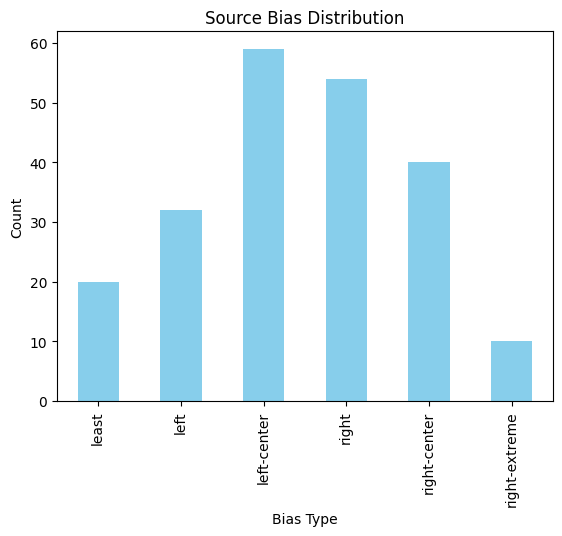

Article Bias Summary:
 count    215.000000
mean       2.455814
std        0.851964
min        1.000000
25%        2.000000
50%        3.000000
75%        3.000000
max        4.000000
Name: article_bias, dtype: float64


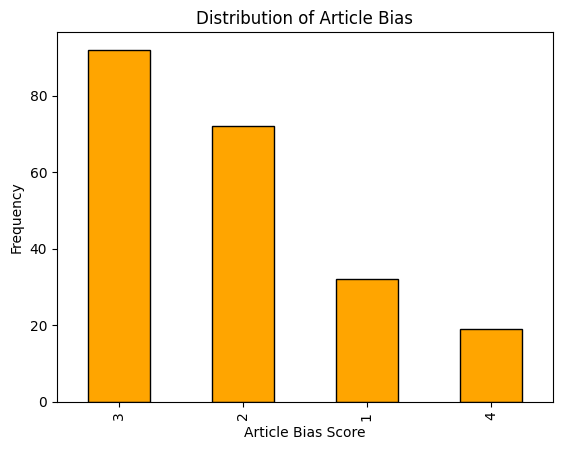

Number of rows after cleaning: 215
Similarity Scores:
                                              reftext  \
0  preuters kentucky state representative dan joh...   
1  preuters kentucky state representative dan joh...   
2  preuters kentucky state representative dan joh...   
3  preuters kentucky state representative dan joh...   
4  preuters kentucky state representative dan joh...   

                                             docbody  similarity_score  
0  plouisville dan johnson posted final message f...          0.392232  
1  plouisville dan johnson posted final message f...          0.392232  
2  plouisville dan johnson posted final message f...          0.392232  
3  plouisville dan johnson posted final message f...          0.392232  
4  pcnn kentucky lawmaker accused sexually assaul...          0.438529  


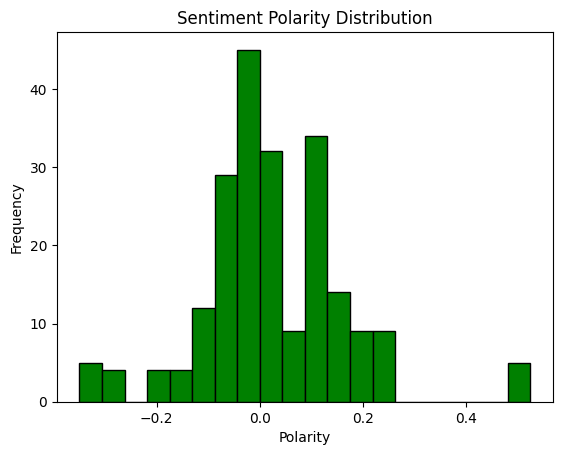

Cleaned and analyzed data saved to cleaned_and_analyzed_biased_sentences1.csv


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
import matplotlib.pyplot as plt

# Step 6: Source level Bias Analysis
# First, correct any misspellings in the labels
cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

# If the 'article_bias' column also contains the misspelling, correct it
if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')

# Now calculate the source bias distribution and then visualize it
source_bias_distribution = cleaned_db['source_bias'].apply(lambda x: 1).groupby(cleaned_db['source_bias']).sum()
print("Source Bias Distribution:\n", source_bias_distribution)

source_bias_distribution.plot(kind='bar', title='Source Bias Distribution', xlabel='Bias Type', ylabel='Count', color='skyblue')
plt.show()

# Step 7: Content Bias Analysis
if 'article_bias' in cleaned_db.columns:
    # Calculating the summary statistics and then computing the frequency distribution of article_bias
    article_bias_summary = cleaned_db['article_bias'].describe()
    print("Article Bias Summary:\n", article_bias_summary)

    bias_counts = cleaned_db['article_bias'].value_counts()

    # Visualize the distribution using bar plot
    bias_counts.plot(kind='bar', title='Distribution of Article Bias', color='orange', edgecolor='black')
    plt.xlabel('Article Bias Score')
    plt.ylabel('Frequency')
    plt.show()

# Step 8: Content Comparison for Bias
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Making sure that no empty rows are present in 'reftext' or 'docbody'
cleaned_db = cleaned_db[(cleaned_db['reftext'].notna()) & (cleaned_db['docbody'].notna())]
cleaned_db = cleaned_db[(cleaned_db['reftext'].str.strip() != "") & (cleaned_db['docbody'].str.strip() != "")]
print(f"Number of rows after cleaning: {len(cleaned_db)}")

# If no valid rows remain then we will exit the process
if len(cleaned_db) == 0:
    print("No valid data available for content comparison. Exiting the process.")
    exit()

# Computing the TF-IDF cosine similarity between reftext and docbody for each row
vectorizer = TfidfVectorizer(stop_words='english')

ref_texts = cleaned_db['reftext']
doc_bodies = cleaned_db['docbody']

similarity_scores = []

# Iterating over each row to compute cosine similarity
for ref_text, doc_body in zip(ref_texts, doc_bodies):
    tfidf_ref = vectorizer.fit_transform([ref_text])  # Vectorize reftext
    tfidf_doc = vectorizer.transform([doc_body])  # Transform docbody using the same vectorizer
    
    similarity = cosine_similarity(tfidf_ref, tfidf_doc)[0, 0]  # Compute cosine similarity
    similarity_scores.append(similarity)

# Adding the similarity scores back to the dataframe
cleaned_db['similarity_score'] = similarity_scores
print("Similarity Scores:\n", cleaned_db[['reftext', 'docbody', 'similarity_score']].head())

# Step 9: Sentiment Analysis 
sentiments = [TextBlob(text).sentiment for text in cleaned_db['docbody']]
cleaned_db['sentiment_polarity'], cleaned_db['sentiment_subjectivity'] = zip(*sentiments)

# Visualize sentiment polarity
cleaned_db['sentiment_polarity'].plot(kind='hist', bins=20, title='Sentiment Polarity Distribution', color='green', edgecolor='black')
plt.xlabel('Polarity')
plt.ylabel('Frequency')
plt.show()

# Step 10: Save and Verify
output_path = 'cleaned_and_analyzed_biased_sentences1.csv'
cleaned_db.to_csv(output_path, index=False)
print(f"Cleaned and analyzed data saved to {output_path}")


Evaluating Random Forest with Cross-Validation...
Random Forest Cross-Validation Accuracy: 0.9883107088989442 ± 0.01564924856318516
Best Params for Random Forest: {'max_depth': None, 'n_estimators': 100}
Random Forest Test Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        16
           3       1.00      0.78      0.88        23
           4       0.71      1.00      0.83        12
           5       1.00      1.00      1.00         2

    accuracy                           0.92        65
   macro avg       0.95      0.96      0.95        65
weighted avg       0.95      0.92      0.93        65



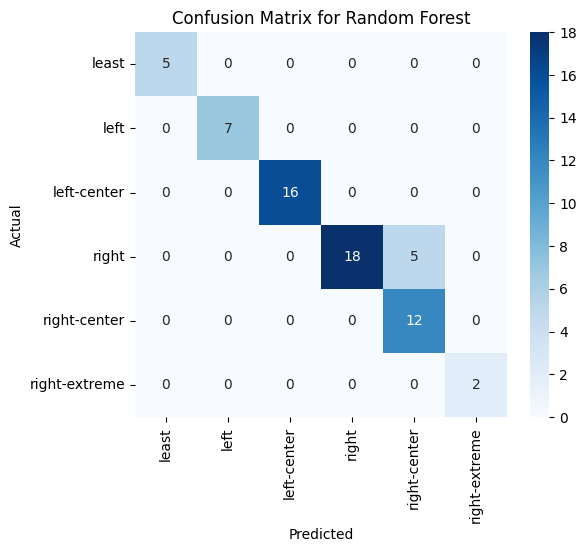

Evaluating SVM with Cross-Validation...
SVM Cross-Validation Accuracy: 0.9883107088989442 ± 0.01564924856318516
SVM Test Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       0.76      1.00      0.86        16
           3       1.00      0.78      0.88        23
           4       1.00      1.00      1.00        12
           5       1.00      1.00      1.00         2

    accuracy                           0.92        65
   macro avg       0.96      0.96      0.96        65
weighted avg       0.94      0.92      0.92        65



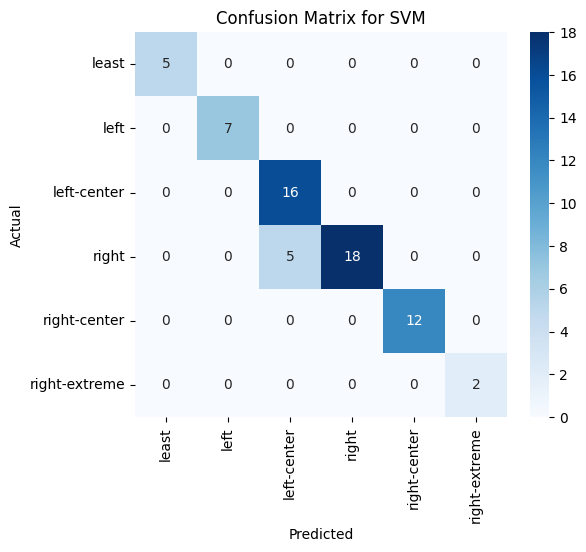

Evaluating Logistic Regression with Cross-Validation...
Logistic Regression Cross-Validation Accuracy: 0.9961538461538462 ± 0.007692307692307709
Logistic Regression Test Accuracy: 0.8615384615384616
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       0.76      1.00      0.86        16
           3       1.00      0.61      0.76        23
           4       0.75      1.00      0.86        12
           5       1.00      1.00      1.00         2

    accuracy                           0.86        65
   macro avg       0.92      0.93      0.91        65
weighted avg       0.90      0.86      0.85        65



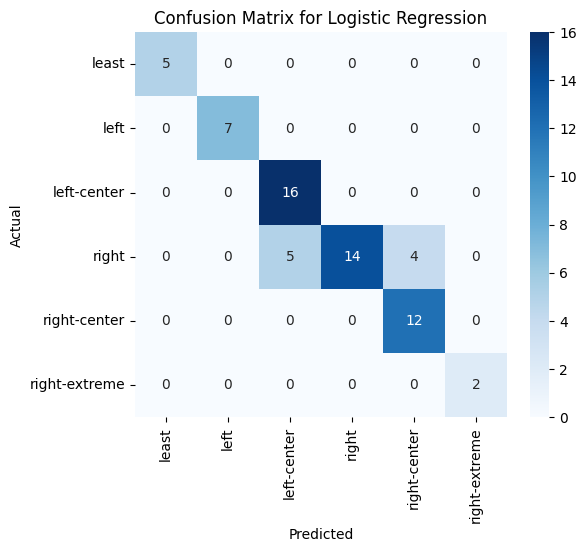

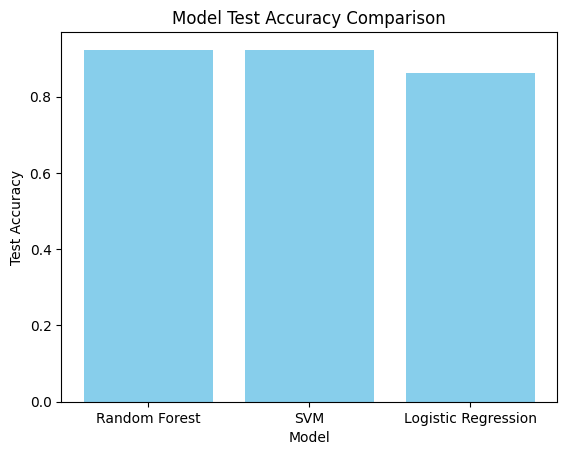

Final Model Results:

Random Forest - CV Accuracy: 0.9883107088989442 ± 0.01564924856318516
Test Accuracy: 0.9230769230769231
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        16
           3       1.00      0.78      0.88        23
           4       0.71      1.00      0.83        12
           5       1.00      1.00      1.00         2

    accuracy                           0.92        65
   macro avg       0.95      0.96      0.95        65
weighted avg       0.95      0.92      0.93        65


SVM - CV Accuracy: 0.9883107088989442 ± 0.01564924856318516
Test Accuracy: 0.9230769230769231
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       0.76    

In [27]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE

# Step 11: Feature Extraction
pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(stop_words='english'))
])

X = pipeline.fit_transform(cleaned_db['docbody'])

# Step 12: Encode the target labels
encoder = LabelEncoder()
encoded_labels = encoder.fit_transform(cleaned_db['source_bias'])

# Step 13: Split the data for training and testing
X_train, X_test, y_train, y_test = train_test_split(X, encoded_labels, test_size=0.3, random_state=42)

# Step 14: Resampling the data through SMOTE to maintain the class balance
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Step 15: Initialize Models with Class Weights for balancing
models = {
    "Random Forest": RandomForestClassifier(class_weight='balanced'),
    "SVM": SVC(class_weight='balanced'),
    "Logistic Regression": LogisticRegression(class_weight='balanced')
}

results = {}

# Hyperparameter grid 
rf_params = {'n_estimators': [100, 200], 'max_depth': [None, 10, 20]}

# Create a  cross-validation 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for model_name, model in models.items():
    print(f"Evaluating {model_name} with Cross-Validation...")

    # Cross-validation scores calculation
    cv_score = cross_val_score(model, X_train_resampled, y_train_resampled, cv=cv, scoring='accuracy')

   
    results[model_name] = {
        'cross_val_mean': cv_score.mean(),
        'cross_val_std': cv_score.std()
    }

    print(f"{model_name} Cross-Validation Accuracy: {cv_score.mean()} ± {cv_score.std()}")

    # Hyperparameter tuning with GridSearchCV 
    if model_name == "Random Forest":
        grid_search = GridSearchCV(model, rf_params, cv=5)
        grid_search.fit(X_train_resampled, y_train_resampled)
        model = grid_search.best_estimator_
        print(f"Best Params for {model_name}: {grid_search.best_params_}")

    
    model.fit(X_train_resampled, y_train_resampled)
    predicted_labels = model.predict(X_test)

    # Calculate accuracy on the test set
    accuracy = accuracy_score(y_test, predicted_labels)

    results[model_name].update({
        'test_accuracy': accuracy,
        'classification_report': classification_report(y_test, predicted_labels),
        'confusion_matrix': confusion_matrix(y_test, predicted_labels)
    })

    print(f"{model_name} Test Accuracy: {accuracy}")
    print(results[model_name]['classification_report'])

    # Create a confusion matrix plot
    cm = results[model_name]['confusion_matrix']
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=encoder.classes_, yticklabels=encoder.classes_)
    plt.title(f"Confusion Matrix for {model_name}")
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Step 16: Compare results of accuracy among all models by visualizing 
model_names = list(results.keys())
accuracies = [results[model]['test_accuracy'] for model in model_names]

plt.bar(model_names, accuracies, color='skyblue')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.title('Model Test Accuracy Comparison')
plt.show()

# Step 7: Printing the final model results
print("Final Model Results:")
for model_name, result in results.items():
    print(f"\n{model_name} - CV Accuracy: {result['cross_val_mean']} ± {result['cross_val_std']}")
    print(f"Test Accuracy: {result['test_accuracy']}")
    print(f"Classification Report:\n{result['classification_report']}")


Sentiment Analysis Results (TextBlob):
       sentiment_polarity  sentiment_subjectivity
count          215.000000              215.000000
mean             0.028580                0.367353
std              0.143809                0.205965
min             -0.350000                0.000000
25%             -0.055556                0.226667
50%              0.021429                0.375000
75%              0.107143                0.477273
max              0.525000                1.000000
Bias Sentiment Comparison (TextBlob):
     source_bias  sentiment_polarity
0          least            0.063210
1           left            0.050756
3          right            0.031989
5  right-extreme            0.020238
4   right-center            0.017907
2    left-center            0.010342
/tmp/ipykernel_110/3312966481.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same eff

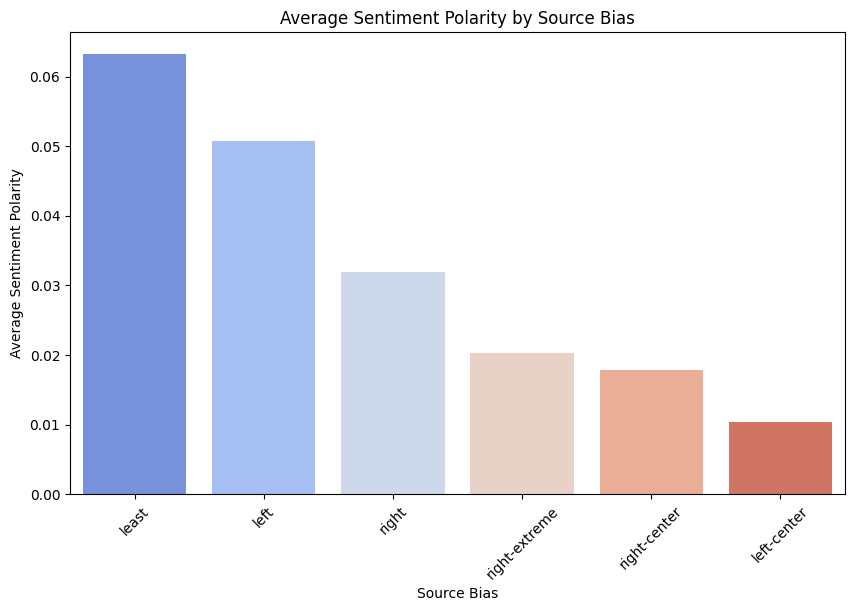

In [29]:
from nltk.sentiment import SentimentIntensityAnalyzer
import seaborn as sns

# step 16: Content Bias Analysis 
print("Sentiment Analysis Results (TextBlob):")
print(cleaned_db[['sentiment_polarity', 'sentiment_subjectivity']].describe())

# ---- create a sentiment comparison dataframe ----
def content_compare_bias_sentiment(df):
    sentiment_comparison = df.groupby('source_bias')['sentiment_polarity'].mean().reset_index()
    sentiment_comparison = sentiment_comparison.sort_values(by='sentiment_polarity', ascending=False)
    return sentiment_comparison

sentiment_comparison = content_compare_bias_sentiment(cleaned_db)
print("Bias Sentiment Comparison (TextBlob):")
print(sentiment_comparison)

# Visualize the sentiment comparison of the above results
plt.figure(figsize=(10, 6))
sns.barplot(x='source_bias', y='sentiment_polarity', data=sentiment_comparison, palette='coolwarm')
plt.title('Average Sentiment Polarity by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Average Sentiment Polarity')
plt.xticks(rotation=45)
plt.show()




Sentiment Analysis Results (Polarity):
               count      mean       std       min       25%       50%  \
source_bias                                                              
least           20.0  0.063210  0.087548 -0.062500  0.009943  0.079545   
left            32.0  0.050756  0.141311 -0.166234 -0.041667  0.021429   
left-center     59.0  0.010342  0.221021 -0.350000 -0.100000 -0.010000   
right           54.0  0.031989  0.099985 -0.200000  0.000000  0.057143   
right-center    40.0  0.017907  0.063484 -0.075000 -0.013889  0.011905   
right-extreme   10.0  0.020238  0.091606 -0.066667 -0.066667  0.020238   

                    75%       max  
source_bias                        
least          0.132812  0.156250  
left           0.250000  0.255682  
left-center    0.095833  0.525000  
right          0.118750  0.150000  
right-center   0.050000  0.116667  
right-extreme  0.107143  0.107143  
Topic 0: ['amy', 'regulation', 'took', 'north', 'tillerson', 'willing', 'rex', '

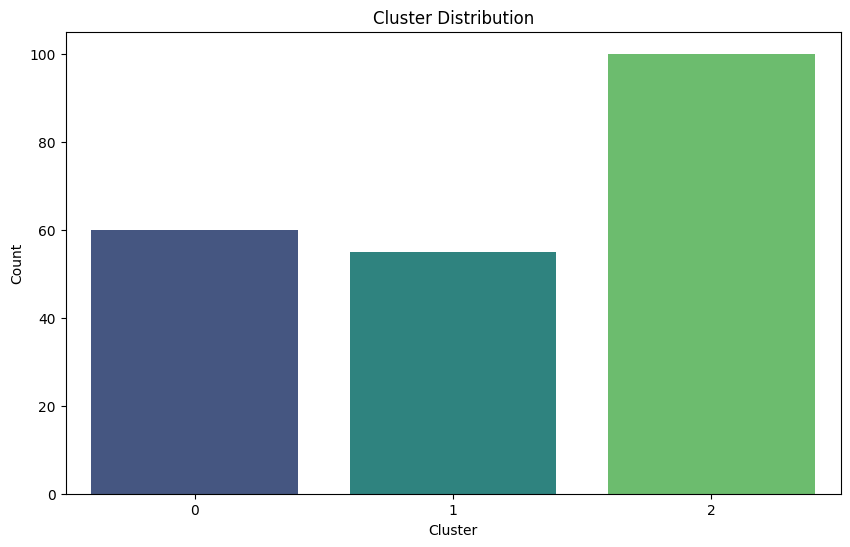

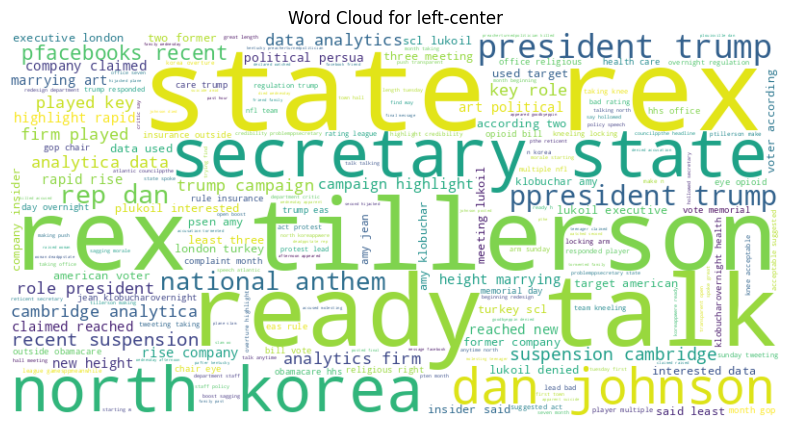

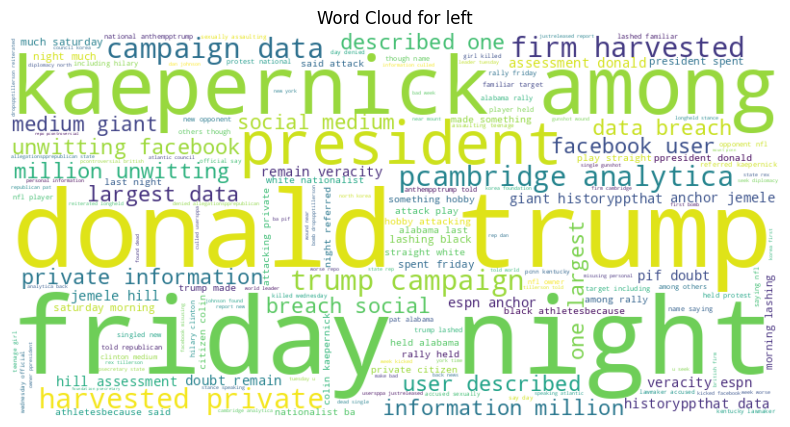

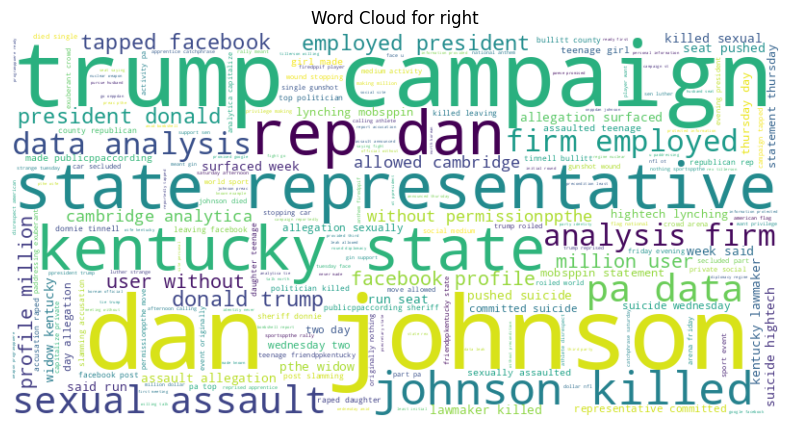

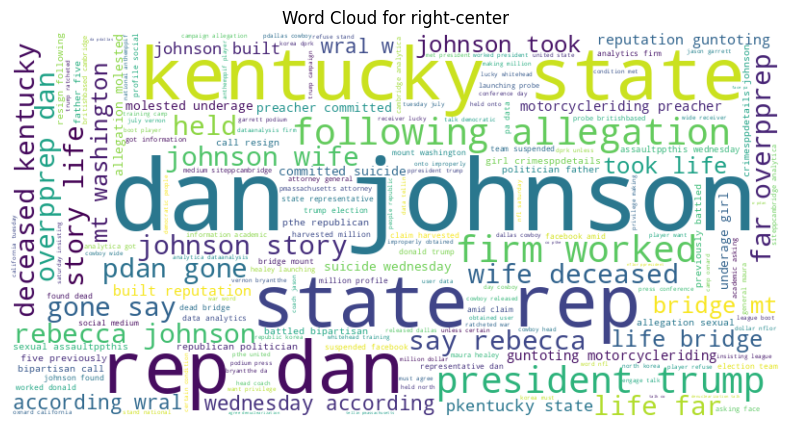

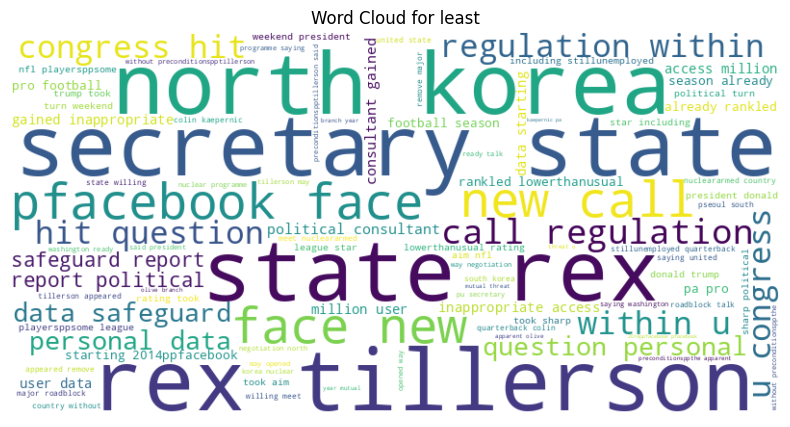

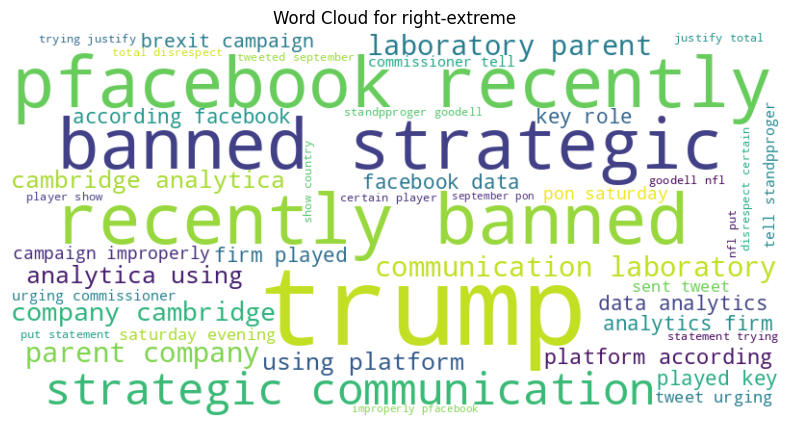

Emotion Analysis Example:
   source_bias                                           emotions
0  left-center  {'help': 0.047619047619047616, 'office': 0.0, ...
1  left-center  {'help': 0.047619047619047616, 'office': 0.0, ...
2  left-center  {'help': 0.047619047619047616, 'office': 0.0, ...
3  left-center  {'help': 0.047619047619047616, 'office': 0.0, ...
4         left  {'help': 0.0, 'office': 0.0, 'dance': 0.0, 'mo...
Analysis Completed. Data Sample:
   id_event    event  date_event  id_article                 source  \
0         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
1         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
2         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
3         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
4         1  Johnson  2017-12-15         2.0              002_CNN_1   

   source_bias                                                url      ref  \
0  left-center  https://www.washingtonpo

In [31]:
from wordcloud import WordCloud
from collections import Counter
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.cluster import KMeans
from empath import Empath


# Step 17: Sentiment Analysis Statistics by Bias
print("Sentiment Analysis Results (Polarity):")
sentiment_stats = cleaned_db.groupby('source_bias')['sentiment_polarity'].describe()
print(sentiment_stats)


# Step 18: Topic Modeling with LDA
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])

lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X)

#  Top words of each topic are printed
vocab = vectorizer.get_feature_names_out()
for idx, topic in enumerate(lda.components_):
    print(f"Topic {idx}:", [vocab[i] for i in topic.argsort()[-10:]])

# Step 19: Text Similarity Analysis
from sklearn.metrics.pairwise import cosine_similarity
similarity_matrix = cosine_similarity(X)

#  Similarities from the first document is printed
print("Text Similarity for First Document:")
print(similarity_matrix[0])

# Step 20: Clustering distribution creation 
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)
cleaned_db['cluster'] = kmeans.labels_

# Visualizing the above cluster distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='cluster', data=cleaned_db, palette='viridis')
plt.title('Cluster Distribution')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.show()

# Step 21: Word Cloud for Bias Categories
def plot_wordcloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(text))
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

for bias in cleaned_db['source_bias'].unique():
    subset_wordcloud = cleaned_db[cleaned_db['source_bias'] == bias]
    plot_wordcloud(subset_wordcloud['docbody'], f'Word Cloud for {bias}')

# Step 22: Emotion Analysis Using NRC Lexicon
from empath import Empath
lexicon = Empath()

def get_emotions(text):
    return lexicon.analyze(text, normalize=True)

# Adding emotion analysis to dataset (process-intensive for large data)
cleaned_db['emotions'] = cleaned_db['docbody'].apply(get_emotions)

print("Emotion Analysis Example:")
print(cleaned_db[['source_bias', 'emotions']].head())

# Step 23: Time-Series Analysis of sentiment
if 'timestamp' in cleaned_db.columns:
    cleaned_db['timestamp'] = pd.to_datetime(cleaned_db['timestamp'])
    sentiment_over_time = cleaned_db.groupby(pd.Grouper(key='timestamp', freq='M'))['sentiment_polarity'].mean()
    plt.figure(figsize=(12, 6))
    plt.plot(sentiment_over_time.index, sentiment_over_time.values, marker='o', color='b')
    plt.title('Sentiment Polarity Over Time')
    plt.xlabel('Time')
    plt.ylabel('Average Sentiment Polarity')
    plt.grid()
    plt.show()


print("Analysis Completed. Data Sample:")
print(cleaned_db.head())


# Pre-processing, sentiment , subjectivity, kmeans clustering,LDA after the test and train data split to evaluate model

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
LDA Topic Modeling Results:
Topic 0:  ['washington', 'bridge', 'life', 'kentucky', 'representative', 'politician', 'kaepernick', 'data', 'dan', 'johnson']
Topic 1:  ['cambridge', 'sexually', 'korea', 'kentucky', 'president', 'rep', 'state', 'talk', 'johnson', 'trump']
Topic 2:  ['department', 'meeting', 'atlantic', 'month', 'diplomacy', 'psecretary', 'tillerson', 'rex', 'family', 'state']
Topic 3:  ['luther', 

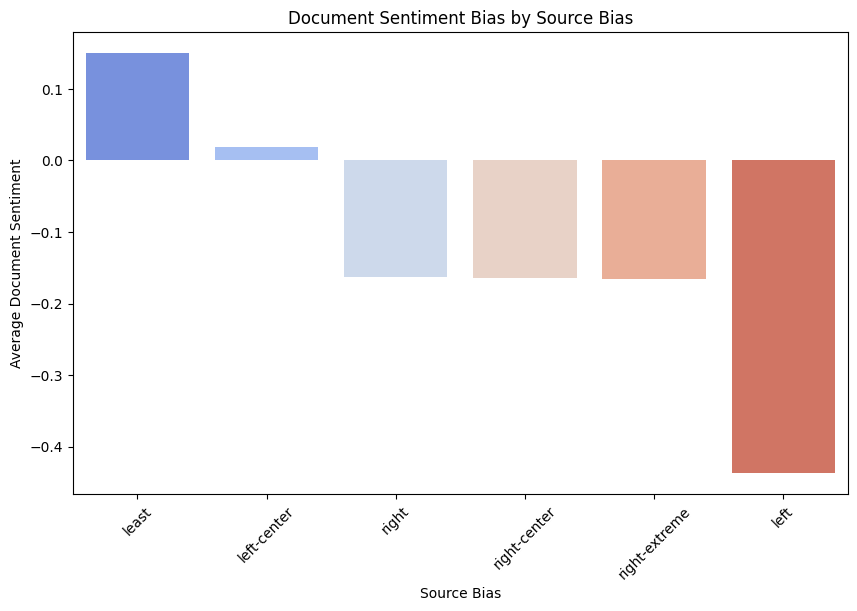

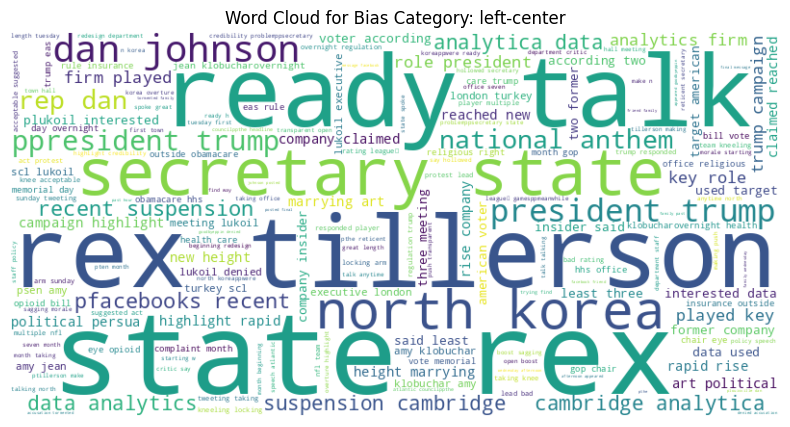

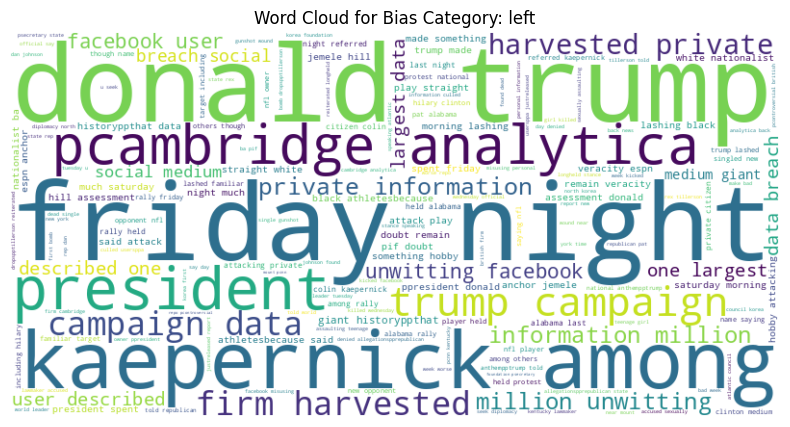

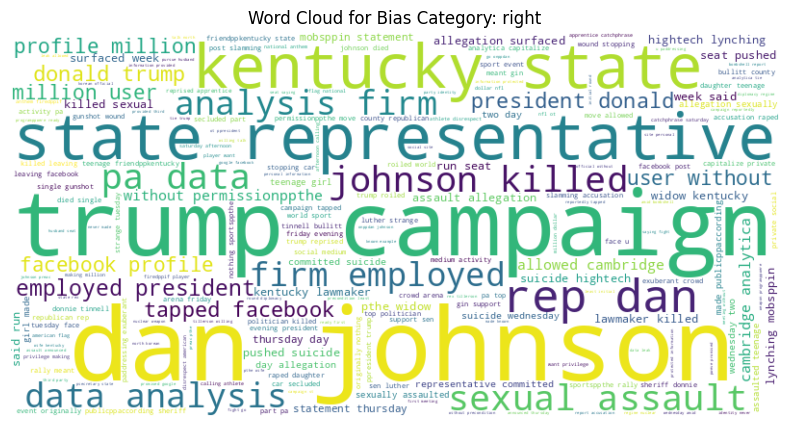

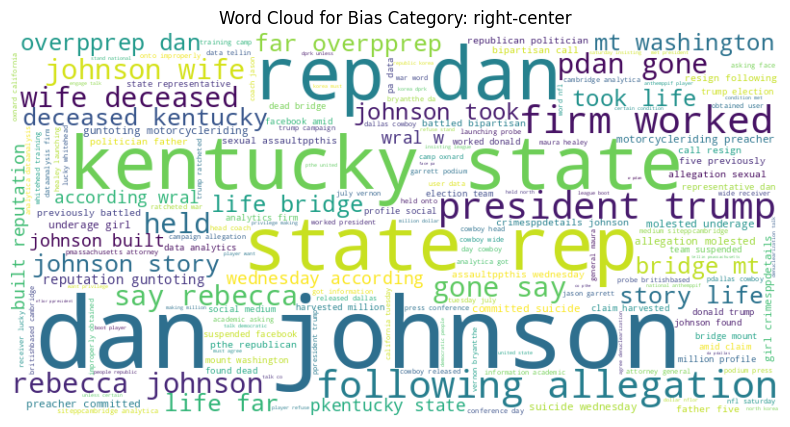

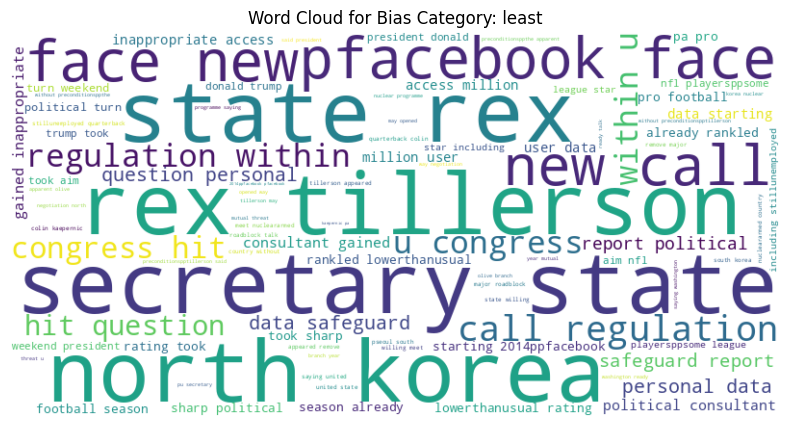

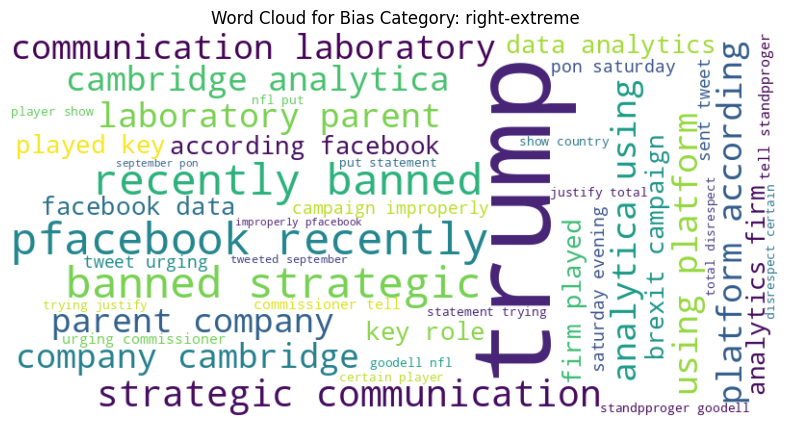

/tmp/ipykernel_112/2958592925.py:234: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='source_bias', y='textblob_subjectivity', data=cleaned_db, palette='coolwarm')


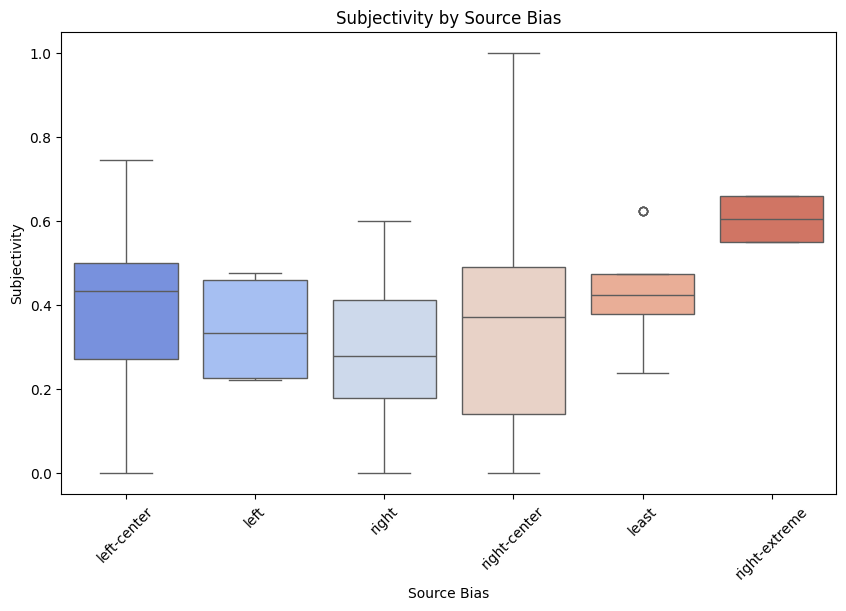

In [15]:
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE
from wordcloud import WordCloud
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt

# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

# Load dataset
db = 'Sora_LREC2020_biasedsentences.csv'  
data = pd.read_csv(db)

# Clean the data
cleaned_db = data.dropna(subset=['reftext', 'docbody'])
cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')

# Text preprocessing
def normalize_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text)

stop_words = set(stopwords.words('english'))

def stopwords_removal_after_tokenization(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(filtered_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(stopwords_removal_after_tokenization)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(stopwords_removal_after_tokenization)

def non_alpha_numeric_removal(text):
    return ''.join([c for c in text if c.isalnum() or c.isspace()])

cleaned_db['reftext'] = cleaned_db['reftext'].apply(non_alpha_numeric_removal)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(non_alpha_numeric_removal)

lemmatizer = WordNetLemmatizer()

def text_lemmatized(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(lemmatized_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(text_lemmatized)

# Apply subjectivity analysis using TextBlob
def textblob_subjectivity(text):
    analysis = TextBlob(text)
    return analysis.sentiment.subjectivity

cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(textblob_subjectivity)

# Sentiment Analysis using VADER (SentimentIntensityAnalyzer)
sia = SentimentIntensityAnalyzer()

# Function to get the sentiment of each sentence
def get_sentence_sentiment(text):
    sentences = sent_tokenize(text)
    sentence_sentiments = []
    for sentence in sentences:
        sentiment_score = sia.polarity_scores(sentence)
        sentence_sentiments.append(sentiment_score['compound'])
    return sentence_sentiments

# Function to get the document's average sentiment
def get_document_sentiment(sentiments):
    return sum(sentiments) / len(sentiments) if sentiments else 0

# Encode labels and split data into train and test sets
le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])

X = cleaned_db['docbody']
X_train, X_test, y_train, y_test = train_test_split(X, cleaned_db['encoded_label'], test_size=0.3, random_state=42)

# TF-IDF Vectorization
vectorizer = TfidfVectorizer(stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Perform KMeans Clustering on training data
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels_train = kmeans.fit_predict(X_train_tfidf)

# Apply Sentiment Analysis to the training data (docbody after train-test split)
train_sentiments = X_train.apply(get_sentence_sentiment)
train_document_sentiments = train_sentiments.apply(get_document_sentiment)

# Add document sentiment to cleaned_db (for the training part)
cleaned_db.loc[X_train.index, 'sentence_sentiments'] = train_sentiments
cleaned_db.loc[X_train.index, 'document_sentiment'] = train_document_sentiments

# If you want to analyze sentiment on the test data, repeat the process for X_test:
test_sentiments = X_test.apply(get_sentence_sentiment)
test_document_sentiments = test_sentiments.apply(get_document_sentiment)
cleaned_db.loc[X_test.index, 'sentence_sentiments'] = test_sentiments
cleaned_db.loc[X_test.index, 'document_sentiment'] = test_document_sentiments

# Perform LDA topic modeling on training data
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features_train = lda.fit_transform(X_train_tfidf)

# Print LDA topic results
print("LDA Topic Modeling Results:")
for topic_idx, topic in enumerate(lda.components_):
    print(f"Topic {topic_idx}: ", [vectorizer.get_feature_names_out()[i] for i in topic.argsort()[-10:]])

# Apply SMOTE for handling class imbalance
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

# Models with Cross-Validation or Hyperparameter Tuning
models = {
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC(),
    "Logistic Regression": LogisticRegression()
}

# Hyperparameter tuning for RandomForest using GridSearchCV
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30]
}

grid_search_rf = GridSearchCV(RandomForestClassifier(), param_grid_rf, cv=5, n_jobs=-1, verbose=1)
grid_search_rf.fit(X_train_smote, y_train_smote)

best_rf_model = grid_search_rf.best_estimator_

# Initialize a dictionary to store results for all models
results = {}

# Train and evaluate all models (RandomForest, SVM, Logistic Regression)
for model_name, model in models.items():
    print(f"Training {model_name}...")
    
    if model_name == "Random Forest":
        model = best_rf_model  # Use the best model found by GridSearchCV for RandomForest

    model.fit(X_train_smote, y_train_smote)
    predicted_labels = model.predict(X_test_tfidf)
    
    accuracy = accuracy_score(y_test, predicted_labels)
    classification_rep = classification_report(y_test, predicted_labels)
    confusion_mat = confusion_matrix(y_test, predicted_labels)
    
    results[model_name] = {
        'accuracy': accuracy,
        'classification_report': classification_rep,
        'confusion_matrix': confusion_mat
    }

# Print results for all models
for model_name, result in results.items():
    print(f"\n{model_name} Results:")
    print(f"Accuracy: {result['accuracy']}")
    print(f"Classification Report:\n{result['classification_report']}")
    print(f"Confusion Matrix:\n{result['confusion_matrix']}")

# Sentiment Bias Analysis by taking the average Sentence Sentiment by Source Bias
def analyze_sentence_bias(df):
    df['sentence_bias'] = df['sentence_sentiments'].apply(lambda x: [classify_sentiment_bias(score) for score in x])
    sentence_bias_summary = df.groupby('source_bias')['sentence_bias'].apply(lambda x: x.explode().value_counts()).unstack(fill_value=0)
    return sentence_bias_summary

sentence_bias_summary = analyze_sentence_bias(cleaned_db)

# Sentiment Analysis Results
print("Sentiment Analysis Results:")
sentiment_stats = cleaned_db.groupby('source_bias')['document_sentiment'].describe()
print(sentiment_stats)

# Content Comparison for Bias
def compare_bias_sentiment(df):
    sentiment_comparison = df.groupby('source_bias')['document_sentiment'].mean().reset_index()
    sentiment_comparison = sentiment_comparison.sort_values(by='document_sentiment', ascending=False)
    return sentiment_comparison

sentiment_comparison = compare_bias_sentiment(cleaned_db)

plt.figure(figsize=(10, 6))
sns.barplot(x='source_bias', y='document_sentiment', data=sentiment_comparison, palette='coolwarm')
plt.title('Document Sentiment Bias by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Average Document Sentiment')
plt.xticks(rotation=45)
plt.show()

# Generate Word Clouds for each Bias Category
def generate_wordcloud(data, bias_category):
    text = " ".join(data[data['source_bias'] == bias_category]['docbody'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Bias Category: {bias_category}')
    plt.show()

for bias in cleaned_db['source_bias'].unique():
    generate_wordcloud(cleaned_db, bias)

# Subjectivity Analysis Visualization
plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='textblob_subjectivity', data=cleaned_db, palette='coolwarm')
plt.title('Subjectivity by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Subjectivity')
plt.xticks(rotation=45)
plt.show()


# Analysis of Random forest model across run1 with no change in the weights of the sentiment and the subjectivity

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
Cross-validation scores: [0.92307692 0.96153846 1.         1.         1.        ]
Average cross-validation score: 0.976923076923077
Random Forest Test Accuracy: 0.8615384615384616
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       0.76      1.00      0.86        16
           3    

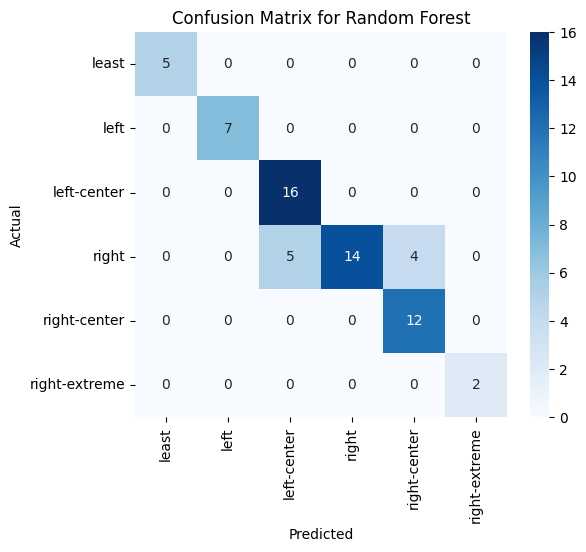

/tmp/ipykernel_110/4091958505.py:186: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')


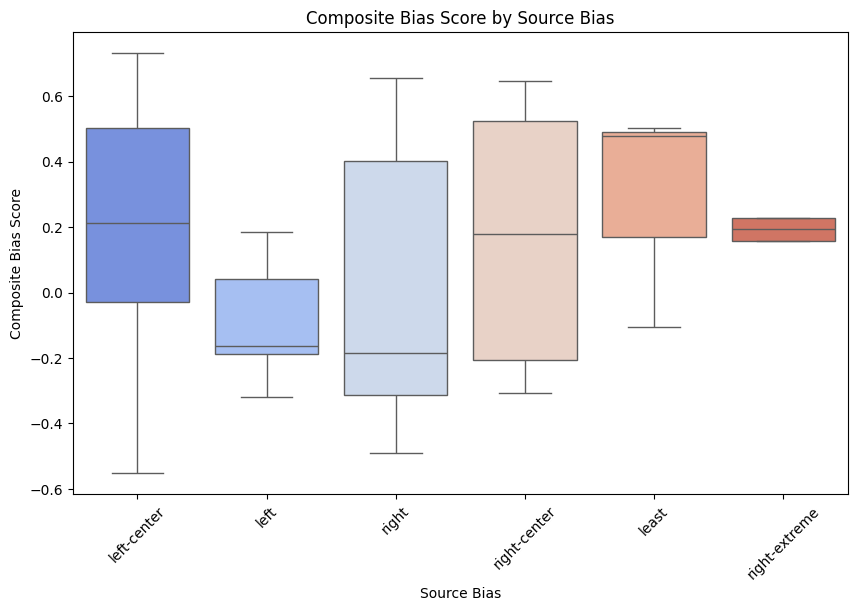

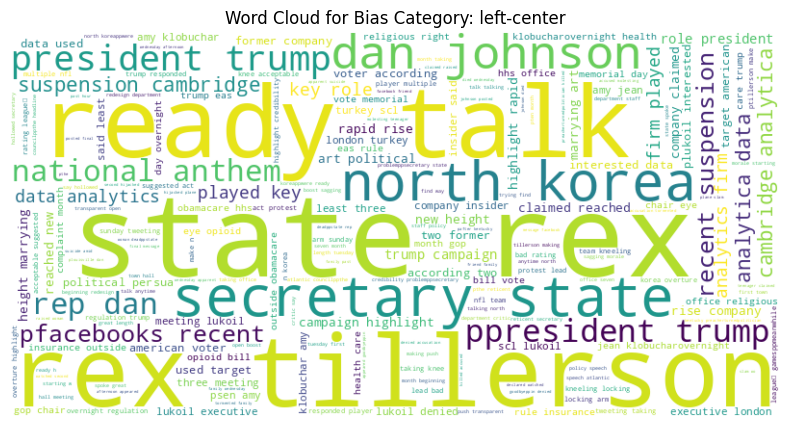

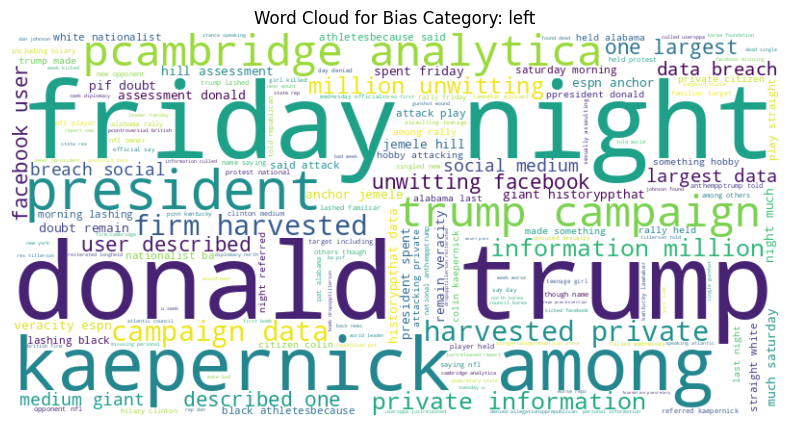

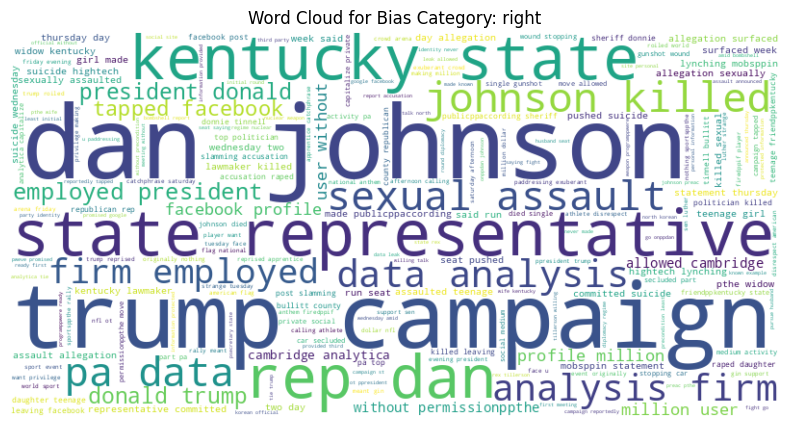

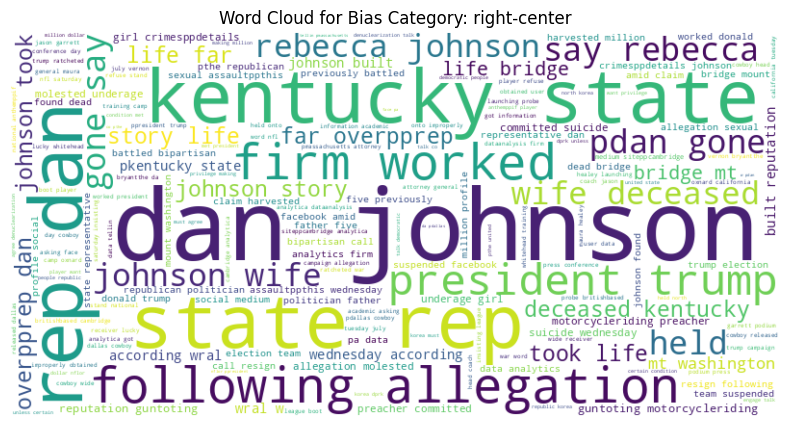

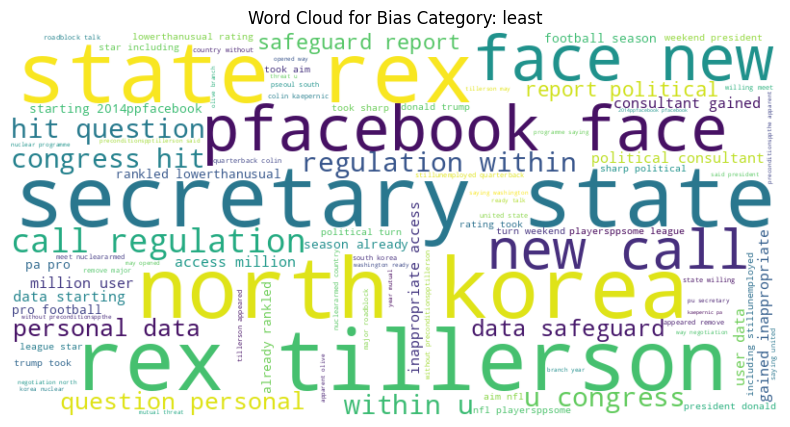

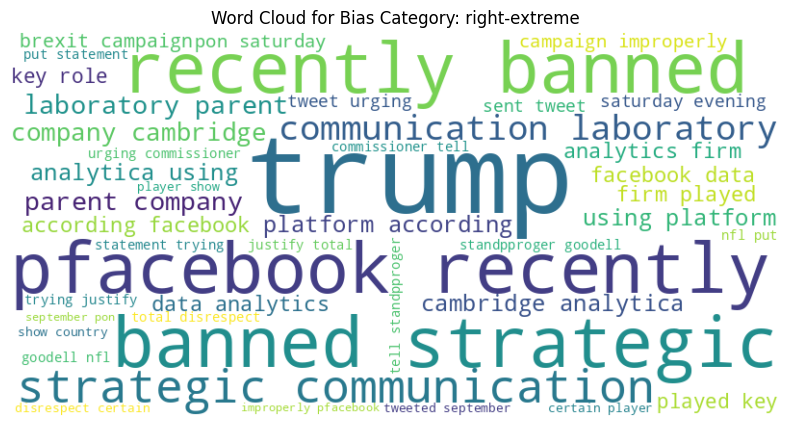

Random Forest Accuracy: 0.8615384615384616
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       0.76      1.00      0.86        16
           3       1.00      0.61      0.76        23
           4       0.75      1.00      0.86        12
           5       1.00      1.00      1.00         2

    accuracy                           0.86        65
   macro avg       0.92      0.93      0.91        65
weighted avg       0.90      0.86      0.85        65



In [8]:
import pandas as pd
import string
import nltk
from wordcloud import WordCloud
from nltk.corpus import stopword
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from textblob import TextBlob
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

# NLTK Downloads
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

# Load dataset
db = 'Sora_LREC2020_biasedsentences.csv'  
data = pd.read_csv(db)

# Data cleaning
cleaned_db = data.dropna(subset=['reftext', 'docbody'])
cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')

# Normalize text
def normalize_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text)

# Stopwords removal after tokenization
stop_words = set(stopwords.words('english'))

def stopwords_removal_after_tokenization(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(filtered_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(stopwords_removal_after_tokenization)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(stopwords_removal_after_tokenization)

# Non-alphabetic characters removal
def non_alpha_numeric_removal(text):
    return ''.join([c for c in text if c.isalnum() or c.isspace()])

cleaned_db['reftext'] = cleaned_db['reftext'].apply(non_alpha_numeric_removal)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(non_alpha_numeric_removal)

# Lemmatization
lemmatizer = WordNetLemmatizer()

def text_lemmatized(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(lemmatized_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(text_lemmatized)

# Sentiment Analysis - Sentence level sentiment
sia = SentimentIntensityAnalyzer()

def get_sentence_sentiment(text):
    sentences = sent_tokenize(text)
    sentence_sentiments = []
    for sentence in sentences:
        sentiment_score = sia.polarity_scores(sentence)
        sentence_sentiments.append(sentiment_score['compound'])
    return sentence_sentiments

def get_document_sentiment(sentiments):
    return sum(sentiments) / len(sentiments) if sentiments else 0

# Compute TextBlob Subjectivity
def compute_subjectivity(text):
    blob = TextBlob(text)
    return blob.sentiment.subjectivity

cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(compute_subjectivity)

# TF-IDF Vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])

# Encode labels
le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])

# Split the data into training and test sets (now we will also keep the index to map later)
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, cleaned_db['encoded_label'], cleaned_db.index, test_size=0.3, random_state=42
)

# Apply SMOTE for handling class imbalance
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Convert the oversampled X_train_smote back to a DataFrame
X_train_smote_df = pd.DataFrame(X_train_smote.toarray(), columns=vectorizer.get_feature_names_out())

# Apply KMeans clustering on the oversampled training data only
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_train_smote_df)

# Now, map the cluster labels back to the oversampled data and then map them to the original indices
# Map the KMeans labels to the corresponding rows in cleaned_db using `train_idx`
cleaned_db.loc[train_idx, 'cluster'] = kmeans_labels[:len(train_idx)]

# Apply LDA (Latent Dirichlet Allocation) on the oversampled training data only
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X_train_smote_df)

# Sentiment Analysis for Document Sentiment (only on the training set)
cleaned_db['sentence_sentiments'] = cleaned_db['docbody'].apply(get_sentence_sentiment)
cleaned_db['document_sentiment'] = cleaned_db['sentence_sentiments'].apply(get_document_sentiment)

def classify_sentiment_bias(sentiment):
    if sentiment > 0:
        return 'positive'
    elif sentiment < 0:
        return 'negative'
    else:
        return 'neutral'

cleaned_db['document_sentiment_bias'] = cleaned_db['document_sentiment'].apply(classify_sentiment_bias)

# Train a Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)

# Cross-validation for evaluating the Random Forest model
cv_scores = cross_val_score(rf_model, X_train_smote, y_train_smote, cv=5)
print(f"Cross-validation scores: {cv_scores}")
print(f"Average cross-validation score: {cv_scores.mean()}")

# Predict on the test data
pred_labels = rf_model.predict(X_test)
accuracy_run_1 = accuracy_score(y_test, pred_labels)

# Model evaluation
print(f"Random Forest Test Accuracy: {accuracy_run_1}")
print(classification_report(y_test, pred_labels))

# Confusion Matrix
cm = confusion_matrix(y_test, pred_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Composite Bias Score Visualization
def compute_weighted_composite_bias(row, sentiment_weight=0.6, subjectivity_weight=0.4, cluster_weight=0.1):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    cluster_score = row['cluster']  # Now, this should work because we've added the cluster column to the DataFrame
    
    # Compute weighted composite bias score
    weighted_score = (sentiment_weight * sentiment_score) + \
                     (subjectivity_weight * subjectivity_score) + \
                     (cluster_weight * cluster_score) 
    return weighted_score

cleaned_db['composite_bias'] = cleaned_db.apply(compute_weighted_composite_bias, axis=1)

# Composite Bias Score visualization by Source Bias
plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Word Cloud Generation for each Bias Category
def generate_wordcloud(data, bias_category):
    text = " ".join(data[data['source_bias'] == bias_category]['docbody'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Bias Category: {bias_category}')
    plt.show()

# Generate Word Clouds for each bias category
for bias in cleaned_db['source_bias'].unique():
    generate_wordcloud(cleaned_db, bias)

# Final Model Results
print(f"Random Forest Accuracy: {accuracy_run_1}")
print(f"Classification Report:\n{classification_report(y_test, pred_labels)}")


# Analysis of Random forest across run2 by decreasing the sentiment weight and subjectivity weight and introducing the topic weight to focus  on the composite bias score effect on the confusion matrix

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!

Summary of Composite Bias Scores:
count    150.000000
mean       0.070334
std        0.341947
min       -0.542060
25%       -0.213490
50%        0.101474
75%        0.391020
max        0.691600
Name: composite_bias, dtype: float64
/tmp/ipykernel_111/3398802830.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and s

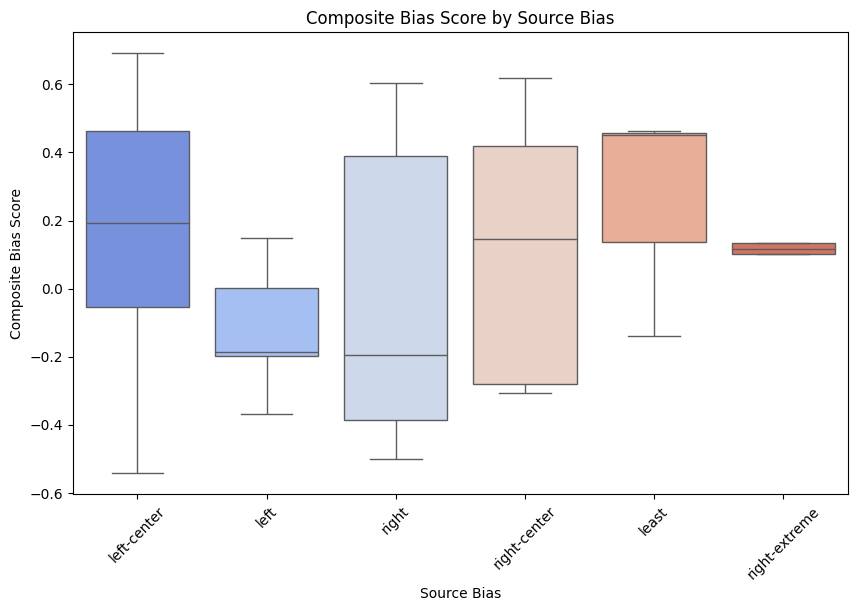

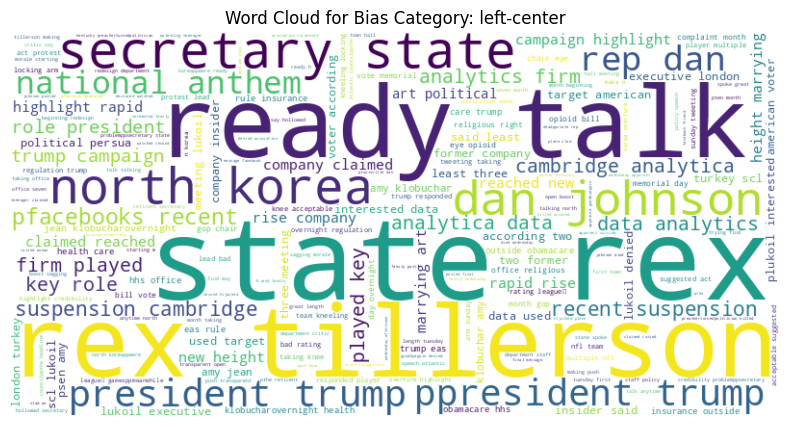

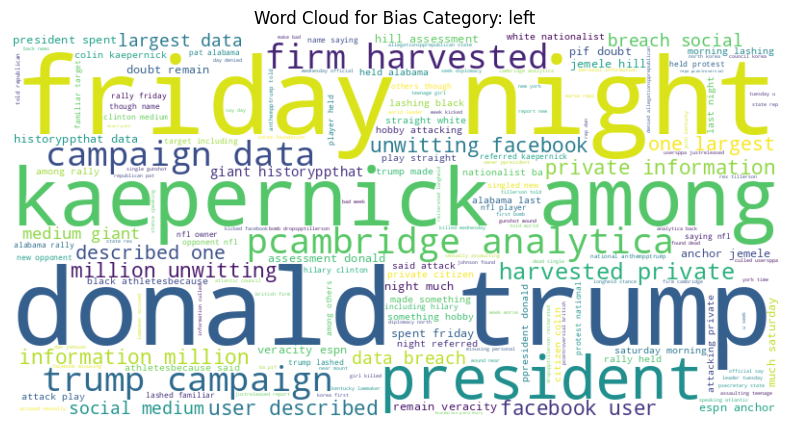

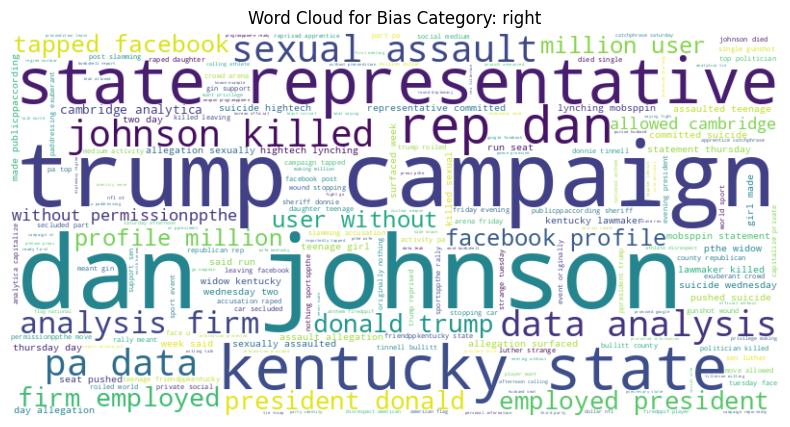

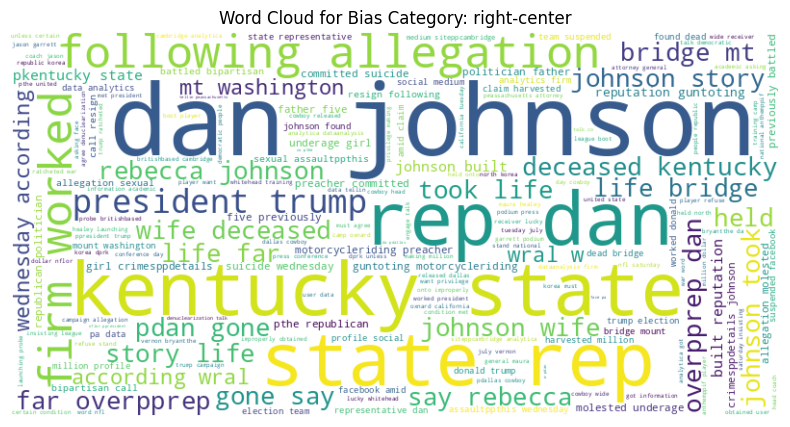

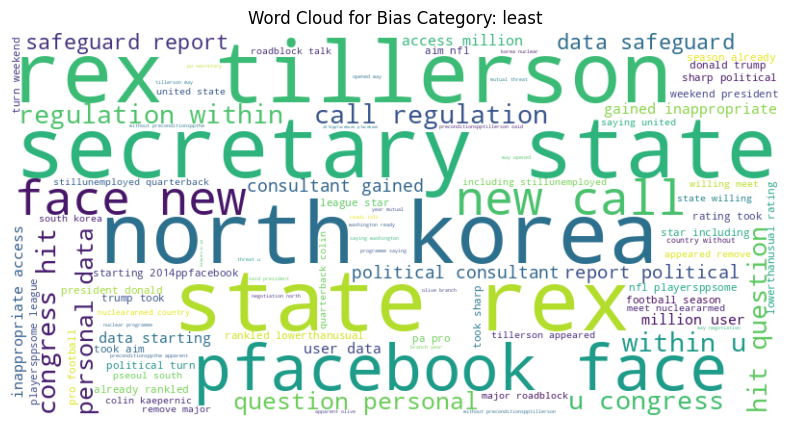

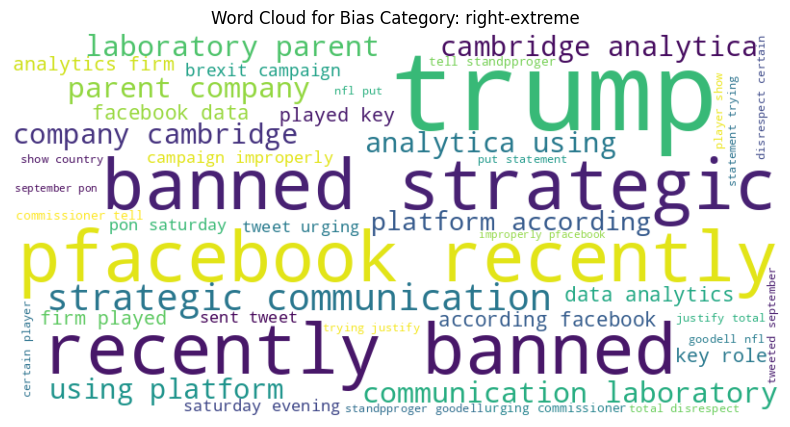

Cross-validation scores: [0.92307692 0.96153846 1.         1.         1.        ]
Average cross-validation score: 0.976923076923077
Random Forest Test Accuracy: 0.8615384615384616
Classification Report:
{'least': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 5}, 'left': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 7}, 'left-center': {'precision': 0.7619047619047619, 'recall': 1.0, 'f1-score': 0.8648648648648648, 'support': 16}, 'right': {'precision': 1.0, 'recall': 0.6086956521739131, 'f1-score': 0.7567567567567568, 'support': 23}, 'right-center': {'precision': 0.75, 'recall': 1.0, 'f1-score': 0.8571428571428571, 'support': 12}, 'right-extreme': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2}, 'accuracy': 0.8615384615384616, 'macro avg': {'precision': 0.9186507936507936, 'recall': 0.9347826086956522, 'f1-score': 0.9131274131274131, 'support': 65}, 'weighted avg': {'precision': 0.8952380952380953, 'recall': 0.8615384615384616, 'f1-score'

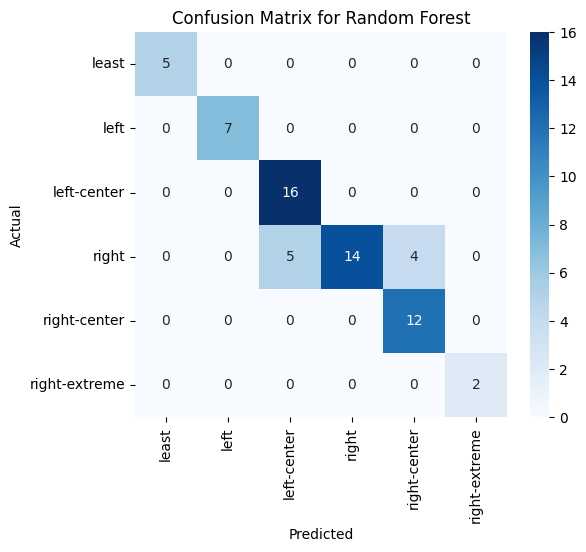

Random Forest Accuracy: 0.8615384615384616


In [11]:
import pandas as pd
import string
import nltk
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from textblob import TextBlob
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

# NLTK Downloads
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

# Load dataset
db = 'Sora_LREC2020_biasedsentences.csv'  
data = pd.read_csv(db)

# Data cleaning
cleaned_db = data.dropna(subset=['reftext', 'docbody'])
cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')

# Normalize text
def normalize_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text)

# Stopwords removal after tokenization
stop_words = set(stopwords.words('english'))

def stopwords_removal_after_tokenization(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(filtered_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(stopwords_removal_after_tokenization)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(stopwords_removal_after_tokenization)

# Non-alphabetic characters removal
def non_alpha_numeric_removal(text):
    return ''.join([c for c in text if c.isalnum() or c.isspace()])

cleaned_db['reftext'] = cleaned_db['reftext'].apply(non_alpha_numeric_removal)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(non_alpha_numeric_removal)

# Lemmatization
lemmatizer = WordNetLemmatizer()

def text_lemmatized(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(lemmatized_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(text_lemmatized)

# Sentiment Analysis - Sentence level sentiment
sia = SentimentIntensityAnalyzer()

def get_sentence_sentiment(text):
    sentences = sent_tokenize(text)
    sentence_sentiments = []
    for sentence in sentences:
        sentiment_score = sia.polarity_scores(sentence)
        sentence_sentiments.append(sentiment_score['compound'])
    return sentence_sentiments

def get_document_sentiment(sentiments):
    return sum(sentiments) / len(sentiments) if sentiments else 0

# Compute TextBlob Subjectivity
def compute_subjectivity(text):
    blob = TextBlob(text)
    return blob.sentiment.subjectivity

cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(compute_subjectivity)

# TF-IDF Vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])

# Encode labels
le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])

# Split the data into training and test sets (now we will also keep the index to map later)
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, cleaned_db['encoded_label'], cleaned_db.index, test_size=0.3, random_state=42
)

# Apply SMOTE for handling class imbalance
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Convert the oversampled X_train_smote back to a DataFrame
X_train_smote_df = pd.DataFrame(X_train_smote.toarray(), columns=vectorizer.get_feature_names_out())

# Apply KMeans clustering on the oversampled training data only
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_train_smote_df)

# Map the KMeans labels back to the oversampled data and then map them to the original indices
cleaned_db.loc[train_idx, 'cluster'] = kmeans_labels[:len(train_idx)]

# Apply LDA (Latent Dirichlet Allocation) on the oversampled training data only
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X_train_smote_df)

# Assign the LDA topic probabilities back to the cleaned_db DataFrame
lda_topic_probs = lda.transform(X_train_smote_df)

# Assign these topic probabilities to the DataFrame
lda_topic_df = pd.DataFrame(lda_topic_probs, columns=[f'lda_topic_{i+1}' for i in range(lda_topic_probs.shape[1])])
cleaned_db.loc[train_idx, lda_topic_df.columns] = lda_topic_df

# Sentiment Analysis for Document Sentiment (only on the training set)
cleaned_db['sentence_sentiments'] = cleaned_db['docbody'].apply(get_sentence_sentiment)
cleaned_db['document_sentiment'] = cleaned_db['sentence_sentiments'].apply(get_document_sentiment)

# Classify sentiment as positive, negative, or neutral
def classify_sentiment_bias(sentiment):
    if sentiment > 0:
        return 'positive'
    elif sentiment < 0:
        return 'negative'
    else:
        return 'neutral'

cleaned_db['document_sentiment_bias'] = cleaned_db['document_sentiment'].apply(classify_sentiment_bias)

# Composite Bias Function
def compute_weighted_composite_bias(row, sentiment_weight=0.6, subjectivity_weight=0.3, cluster_weight=0.05, topic_weight=0.05):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    cluster_score = row['cluster']  # KMeans cluster label
    topic_scores = row[[f'lda_topic_{i+1}' for i in range(5)]].values  # LDA topic probabilities

    # Compute the weighted average of the LDA topic probabilities (taking the mean of the topic scores)
    lda_topic_score = topic_scores.mean()  # Mean of the 5 topic scores

    # Compute the final composite bias score
    weighted_score = (sentiment_weight * sentiment_score) + \
                     (subjectivity_weight * subjectivity_score) + \
                     (cluster_weight * cluster_score) + \
                     (topic_weight * lda_topic_score)
    return weighted_score

# Compute the composite bias score
cleaned_db['composite_bias'] = cleaned_db.apply(compute_weighted_composite_bias, axis=1)

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

# Composite Bias Score visualization by Source Bias
plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Word Cloud Generation for each Bias Category
def generate_wordcloud(data, bias_category):
    text = " ".join(data[data['source_bias'] == bias_category]['docbody'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Bias Category: {bias_category}')
    plt.show()

# Generate Word Clouds for each bias category
for bias in cleaned_db['source_bias'].unique():
    generate_wordcloud(cleaned_db, bias)

# Train a Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)

# Cross-validation for evaluating the Random Forest model
cv_scores_2 = cross_val_score(rf_model, X_train_smote, y_train_smote, cv=5)
print(f"Cross-validation scores: {cv_scores_2}")
print(f"Average cross-validation score: {cv_scores_2.mean()}")

# Predict on the test data
pred_labels2 = rf_model.predict(X_test)
accuracy_run_2 = accuracy_score(y_test, pred_labels2)

# Model evaluation
print(f"Random Forest Test Accuracy: {accuracy_run_2}")
classification_report_2 = classification_report(y_test, pred_labels2, target_names=le.classes_, output_dict=True)
print(f"Classification Report:\n{classification_report_2}")

# Print recall for each class
for label, metrics in classification_report_2.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")

# Confusion Matrix
cm = confusion_matrix(y_test, pred_labels2)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Final Model Results
print(f"Random Forest Accuracy: {accuracy_run_2}")


# Analysis of Random forest across run3 by increasing the sentiment weight, subjectivity weight but decreasing the topic weight

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!

Summary of Composite Bias Scores:
count    150.000000
mean       0.080227
std        0.325641
min       -0.512060
25%       -0.188905
50%        0.065403
75%        0.399353
max        0.671600
Name: composite_bias, dtype: float64
/tmp/ipykernel_111/104829181.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and se

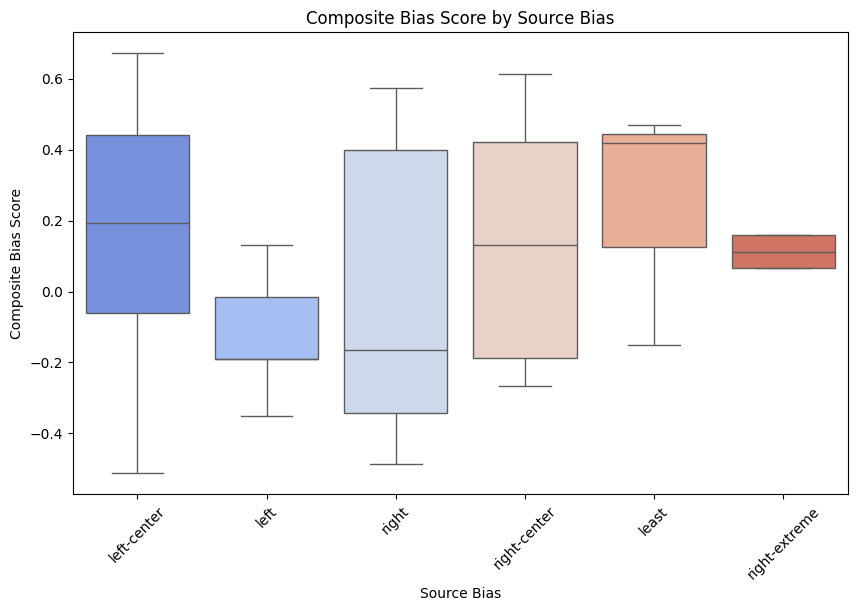

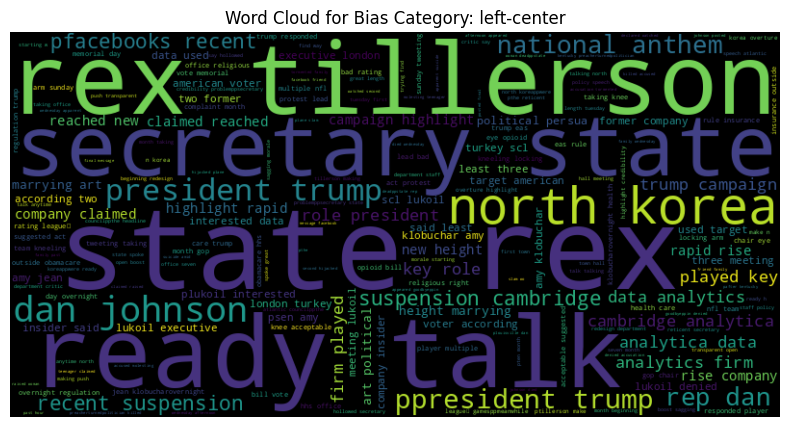

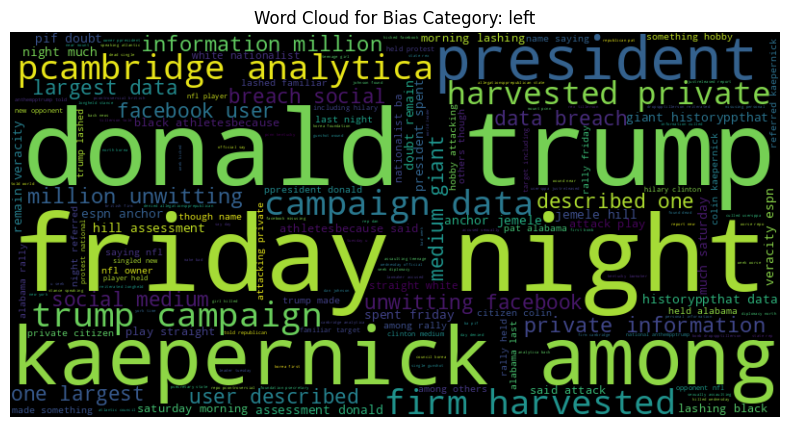

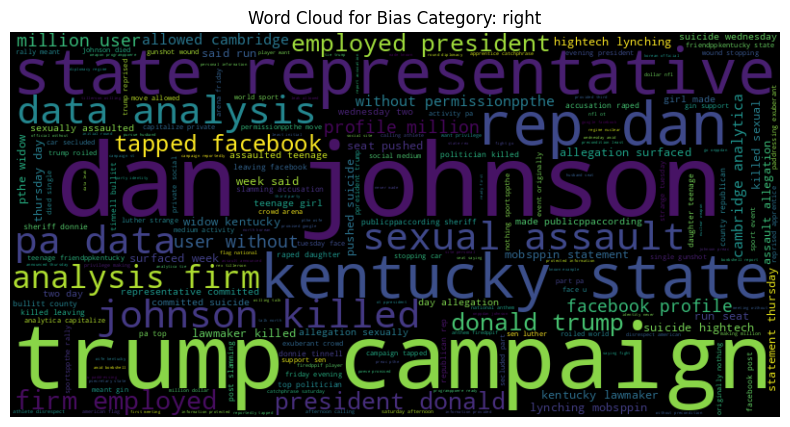

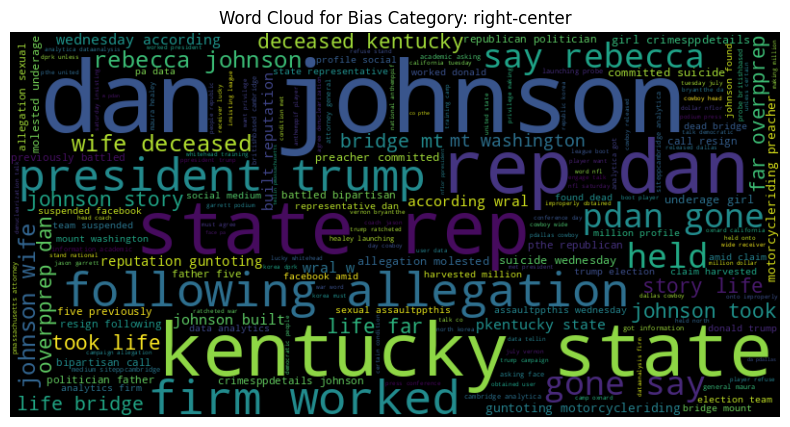

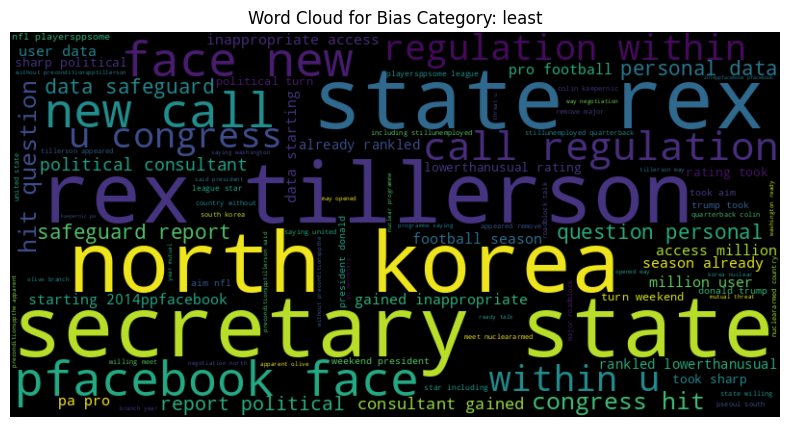

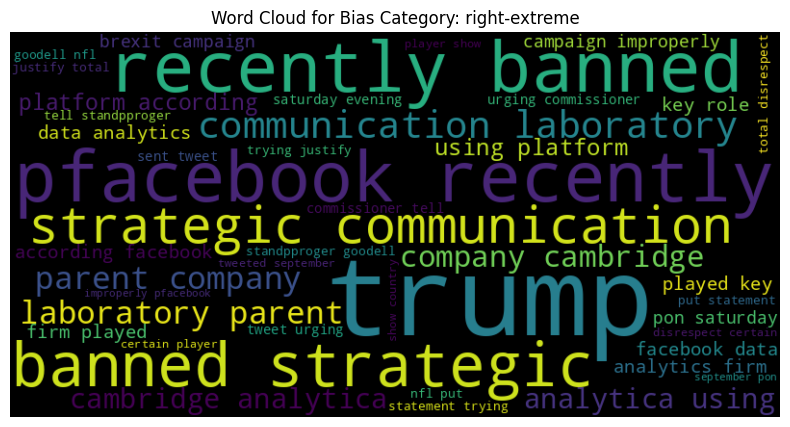

Cross-validation scores: [0.92307692 0.96153846 1.         1.         1.        ]
Average cross-validation score: 0.976923076923077
Random Forest Test Accuracy: 0.8615384615384616
Classification Report:
{'least': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 5}, 'left': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 7}, 'left-center': {'precision': 0.7619047619047619, 'recall': 1.0, 'f1-score': 0.8648648648648648, 'support': 16}, 'right': {'precision': 1.0, 'recall': 0.6086956521739131, 'f1-score': 0.7567567567567568, 'support': 23}, 'right-center': {'precision': 0.75, 'recall': 1.0, 'f1-score': 0.8571428571428571, 'support': 12}, 'right-extreme': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2}, 'accuracy': 0.8615384615384616, 'macro avg': {'precision': 0.9186507936507936, 'recall': 0.9347826086956522, 'f1-score': 0.9131274131274131, 'support': 65}, 'weighted avg': {'precision': 0.8952380952380953, 'recall': 0.8615384615384616, 'f1-score'

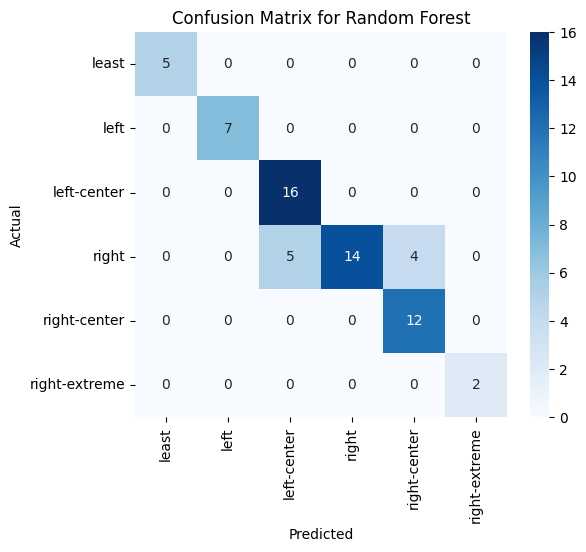

Random Forest Accuracy: 0.8615384615384616


In [13]:
import pandas as pd
import string
import nltk
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from textblob import TextBlob
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

# NLTK Downloads
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

# Load dataset
db = 'Sora_LREC2020_biasedsentences.csv'  
data = pd.read_csv(db)

# Data cleaning
cleaned_db = data.dropna(subset=['reftext', 'docbody'])
cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')

# Normalize text
def normalize_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text)

# Stopwords removal after tokenization
stop_words = set(stopwords.words('english'))

def stopwords_removal_after_tokenization(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(filtered_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(stopwords_removal_after_tokenization)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(stopwords_removal_after_tokenization)

# Non-alphabetic characters removal
def non_alpha_numeric_removal(text):
    return ''.join([c for c in text if c.isalnum() or c.isspace()])

cleaned_db['reftext'] = cleaned_db['reftext'].apply(non_alpha_numeric_removal)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(non_alpha_numeric_removal)

# Lemmatization
lemmatizer = WordNetLemmatizer()

def text_lemmatized(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(lemmatized_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(text_lemmatized)

# Sentiment Analysis - Sentence level sentiment
sia = SentimentIntensityAnalyzer()

def get_sentence_sentiment(text):
    sentences = sent_tokenize(text)
    sentence_sentiments = []
    for sentence in sentences:
        sentiment_score = sia.polarity_scores(sentence)
        sentence_sentiments.append(sentiment_score['compound'])
    return sentence_sentiments

def get_document_sentiment(sentiments):
    return sum(sentiments) / len(sentiments) if sentiments else 0

# Compute TextBlob Subjectivity
def compute_subjectivity(text):
    blob = TextBlob(text)
    return blob.sentiment.subjectivity

cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(compute_subjectivity)

# TF-IDF Vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])

# Encode labels
le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])

# Split the data into training and test sets (now we will also keep the index to map later)
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, cleaned_db['encoded_label'], cleaned_db.index, test_size=0.3, random_state=42
)

# Apply SMOTE for handling class imbalance
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Convert the oversampled X_train_smote back to a DataFrame
X_train_smote_df = pd.DataFrame(X_train_smote.toarray(), columns=vectorizer.get_feature_names_out())

# Apply KMeans clustering on the oversampled training data only
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_train_smote_df)

# Map the KMeans labels back to the oversampled data and then map them to the original indices
cleaned_db.loc[train_idx, 'cluster'] = kmeans_labels[:len(train_idx)]

# Apply LDA (Latent Dirichlet Allocation) on the oversampled training data only
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X_train_smote_df)

# Assign the LDA topic probabilities back to the cleaned_db DataFrame
lda_topic_probs = lda.transform(X_train_smote_df)

# Assign these topic probabilities to the DataFrame
lda_topic_df = pd.DataFrame(lda_topic_probs, columns=[f'lda_topic_{i+1}' for i in range(lda_topic_probs.shape[1])])
cleaned_db.loc[train_idx, lda_topic_df.columns] = lda_topic_df
 
# Sentiment Analysis for Document Sentiment (only on the training set)
cleaned_db['sentence_sentiments'] = cleaned_db['docbody'].apply(get_sentence_sentiment)
cleaned_db['document_sentiment'] = cleaned_db['sentence_sentiments'].apply(get_document_sentiment)

# Classify sentiment as positive, negative, or neutral
def classify_sentiment_bias(sentiment):
    if sentiment > 0:
        return 'positive'
    elif sentiment < 0:
        return 'negative'
    else:
        return 'neutral'

cleaned_db['document_sentiment_bias'] = cleaned_db['document_sentiment'].apply(classify_sentiment_bias)

# Composite Bias Function
def compute_weighted_composite_bias(row, sentiment_weight=0.6, subjectivity_weight=0.2, cluster_weight=0.1, topic_weight=0.2):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    cluster_score = row['cluster']  # KMeans cluster label
    topic_scores = row[[f'lda_topic_{i+1}' for i in range(5)]].values  # LDA topic probabilities

    # Compute the weighted average of the LDA topic probabilities (taking the mean of the topic scores)
    lda_topic_score = topic_scores.mean()  # Mean of the 5 topic scores

    # Compute the final composite bias score
    weighted_score = (sentiment_weight * sentiment_score) + \
                     (subjectivity_weight * subjectivity_score) + \
                     (cluster_weight * cluster_score) + \
                     (topic_weight * lda_topic_score)
    return weighted_score

# Compute the composite bias score
cleaned_db['composite_bias'] = cleaned_db.apply(compute_weighted_composite_bias, axis=1)

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

# Composite Bias Score visualization by Source Bias
plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Word Cloud Generation for each Bias Category
def generate_wordcloud(data, bias_category):
    text = " ".join(data[data['source_bias'] == bias_category]['docbody'])
    wordcloud = WordCloud(width=800, height=400, background_color='black').generate(text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Bias Category: {bias_category}')
    plt.show()

# Generate Word Clouds for each bias category
for bias in cleaned_db['source_bias'].unique():
    generate_wordcloud(cleaned_db, bias)

# Train a Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)

# Cross-validation for evaluating the Random Forest model
cv_scores_3 = cross_val_score(rf_model, X_train_smote, y_train_smote, cv=5)
print(f"Cross-validation scores: {cv_scores_3}")
print(f"Average cross-validation score: {cv_scores_3.mean()}")

# Predict on the test data
pred_labels3 = rf_model.predict(X_test)
accuracy_run_3 = accuracy_score(y_test, pred_labels3)

# Model evaluation
print(f"Random Forest Test Accuracy: {accuracy_run_3}")
classification_report_3 = classification_report(y_test, pred_labels3, target_names=le.classes_, output_dict=True)
print(f"Classification Report:\n{classification_report_3}")

# Print recall for each class
for label, metrics in classification_report_3.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")

# Confusion Matrix
cm = confusion_matrix(y_test, pred_labels3)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Final Model Results
print(f"Random Forest Accuracy: {accuracy_run_3}")


# Analysis of Random forest across run4 by decreasing the sentiment, increasing subjectivity and decreasing the topic weights

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!

Summary of Composite Bias Scores:
count    150.000000
mean       0.112117
std        0.300754
min       -0.476055
25%       -0.106258
50%        0.097500
75%        0.352185
max        0.696431
Name: composite_bias, dtype: float64
/tmp/ipykernel_111/1181266869.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and s

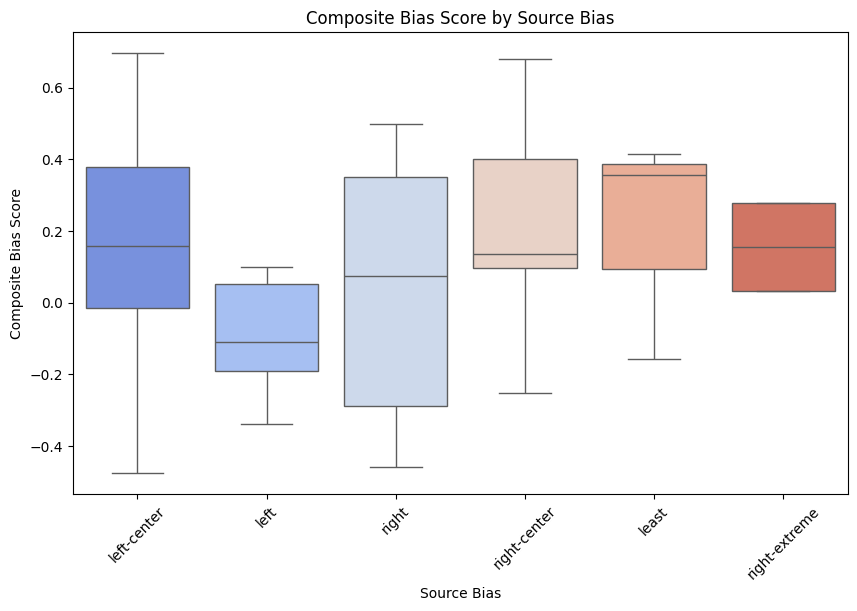

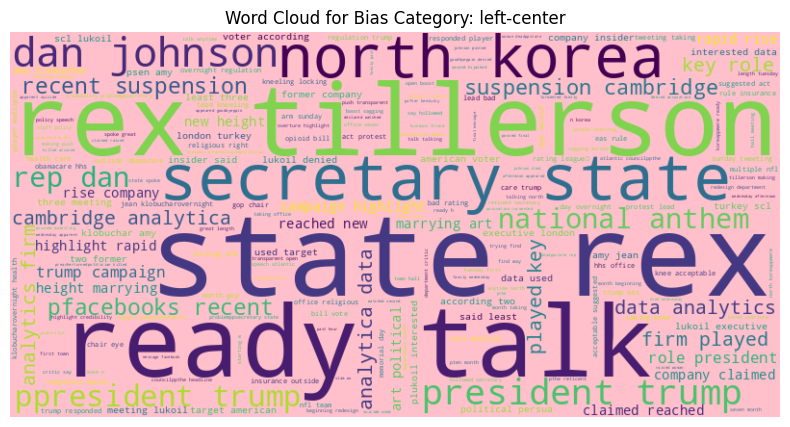

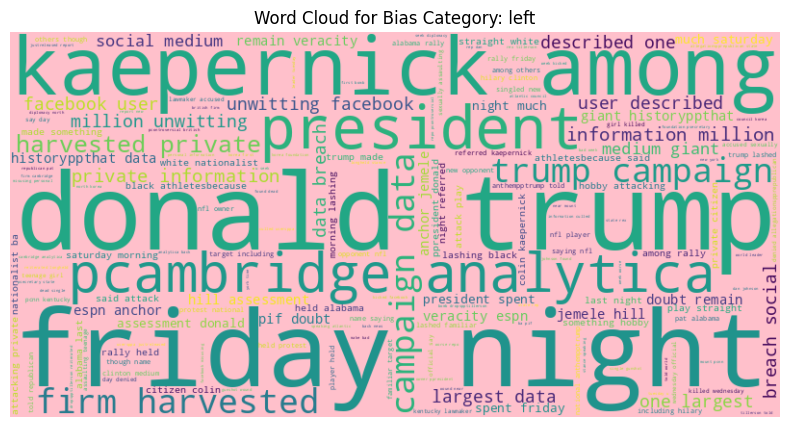

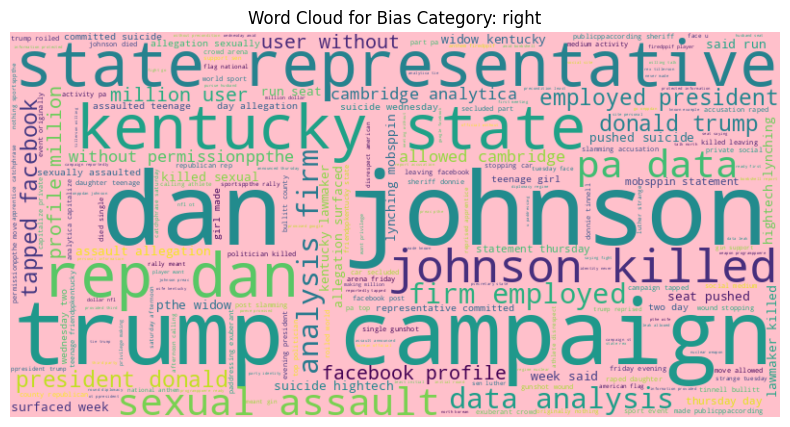

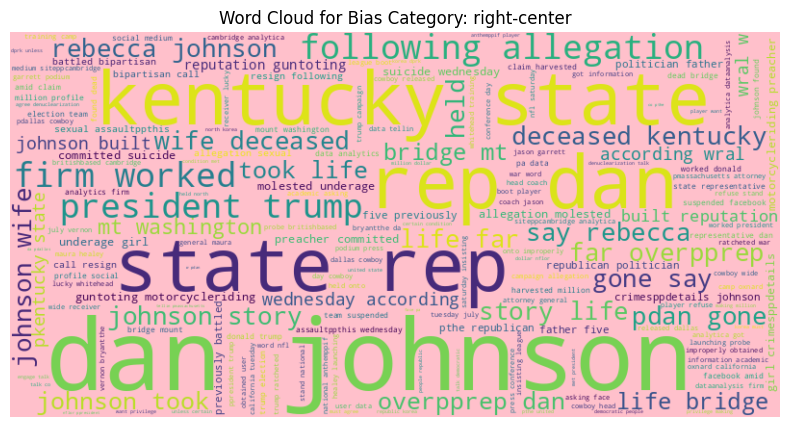

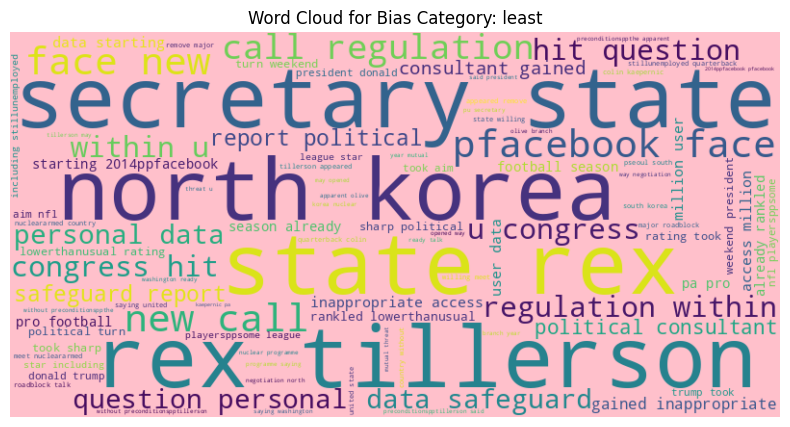

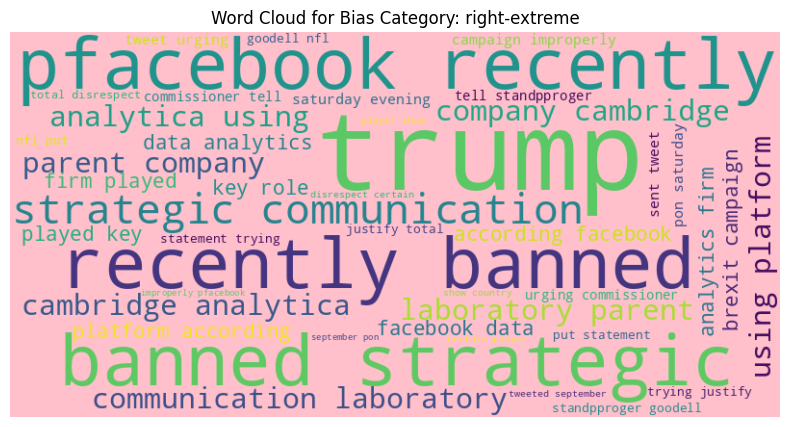

Cross-validation scores: [0.92307692 0.96153846 1.         1.         1.        ]
Average cross-validation score: 0.976923076923077
Random Forest Test Accuracy: 0.8615384615384616
Classification Report:
{'least': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 5}, 'left': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 7}, 'left-center': {'precision': 0.7619047619047619, 'recall': 1.0, 'f1-score': 0.8648648648648648, 'support': 16}, 'right': {'precision': 1.0, 'recall': 0.6086956521739131, 'f1-score': 0.7567567567567568, 'support': 23}, 'right-center': {'precision': 0.75, 'recall': 1.0, 'f1-score': 0.8571428571428571, 'support': 12}, 'right-extreme': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2}, 'accuracy': 0.8615384615384616, 'macro avg': {'precision': 0.9186507936507936, 'recall': 0.9347826086956522, 'f1-score': 0.9131274131274131, 'support': 65}, 'weighted avg': {'precision': 0.8952380952380953, 'recall': 0.8615384615384616, 'f1-score'

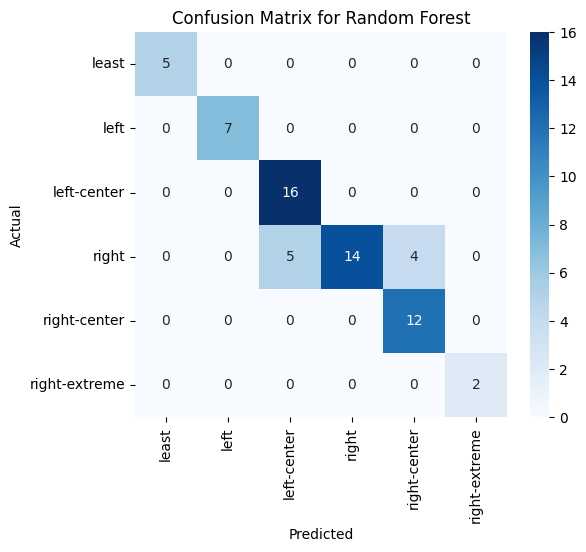

Random Forest Accuracy: 0.8615384615384616


In [26]:
import pandas as pd
import string
import nltk
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from textblob import TextBlob
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

# NLTK Downloads
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

# Load dataset
db = 'Sora_LREC2020_biasedsentences.csv'  
data = pd.read_csv(db)

# Data cleaning
cleaned_db = data.dropna(subset=['reftext', 'docbody'])
cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')

# Normalize text
def normalize_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text)

# Stopwords removal after tokenization
stop_words = set(stopwords.words('english'))

def stopwords_removal_after_tokenization(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(filtered_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(stopwords_removal_after_tokenization)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(stopwords_removal_after_tokenization)

# Non-alphabetic characters removal
def non_alpha_numeric_removal(text):
    return ''.join([c for c in text if c.isalnum() or c.isspace()])

cleaned_db['reftext'] = cleaned_db['reftext'].apply(non_alpha_numeric_removal)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(non_alpha_numeric_removal)

# Lemmatization
lemmatizer = WordNetLemmatizer()

def text_lemmatized(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(lemmatized_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(text_lemmatized)

# Sentiment Analysis - Sentence level sentiment
sia = SentimentIntensityAnalyzer()

def get_sentence_sentiment(text):
    sentences = sent_tokenize(text)
    sentence_sentiments = []
    for sentence in sentences:
        sentiment_score = sia.polarity_scores(sentence)
        sentence_sentiments.append(sentiment_score['compound'])
    return sentence_sentiments

def get_document_sentiment(sentiments):
    return sum(sentiments) / len(sentiments) if sentiments else 0

# Compute TextBlob Subjectivity
def compute_subjectivity(text):
    blob = TextBlob(text)
    return blob.sentiment.subjectivity

cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(compute_subjectivity)

# TF-IDF Vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])

# Encode labels
le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])

# Split the data into training and test sets (now we will also keep the index to map later)
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, cleaned_db['encoded_label'], cleaned_db.index, test_size=0.3, random_state=42
)

# Apply SMOTE for handling class imbalance
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Convert the oversampled X_train_smote back to a DataFrame
X_train_smote_df = pd.DataFrame(X_train_smote.toarray(), columns=vectorizer.get_feature_names_out())

# Apply KMeans clustering on the oversampled training data only
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_train_smote_df)

# Map the KMeans labels back to the oversampled data and then map them to the original indices
cleaned_db.loc[train_idx, 'cluster'] = kmeans_labels[:len(train_idx)]

# Apply LDA (Latent Dirichlet Allocation) on the oversampled training data only
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X_train_smote_df)

# Assign the LDA topic probabilities back to the cleaned_db DataFrame
lda_topic_probs = lda.transform(X_train_smote_df)

# Assign these topic probabilities to the DataFrame
lda_topic_df = pd.DataFrame(lda_topic_probs, columns=[f'lda_topic_{i+1}' for i in range(lda_topic_probs.shape[1])])
cleaned_db.loc[train_idx, lda_topic_df.columns] = lda_topic_df

# Sentiment Analysis for Document Sentiment (only on the training set)
cleaned_db['sentence_sentiments'] = cleaned_db['docbody'].apply(get_sentence_sentiment)
cleaned_db['document_sentiment'] = cleaned_db['sentence_sentiments'].apply(get_document_sentiment)

# Classify sentiment as positive, negative, or neutral
def classify_sentiment_bias(sentiment):
    if sentiment > 0:
        return 'positive'
    elif sentiment < 0:
        return 'negative'
    else:
        return 'neutral'

cleaned_db['document_sentiment_bias'] = cleaned_db['document_sentiment'].apply(classify_sentiment_bias)

# Composite Bias Function
def compute_weighted_composite_bias(row, sentiment_weight=0.55, subjectivity_weight=0.15, cluster_weight=0.25, topic_weight=0.15):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    cluster_score = row['cluster']  # KMeans cluster label
    topic_scores = row[[f'lda_topic_{i+1}' for i in range(5)]].values  # LDA topic probabilities

    # Compute the weighted average of the LDA topic probabilities (taking the mean of the topic scores)
    lda_topic_score = topic_scores.mean()  # Mean of the 5 topic scores

    # Compute the final composite bias score
    weighted_score = (sentiment_weight * sentiment_score) + \
                     (subjectivity_weight * subjectivity_score) + \
                     (cluster_weight * cluster_score) + \
                     (topic_weight * lda_topic_score)
    return weighted_score

# Compute the composite bias score
cleaned_db['composite_bias'] = cleaned_db.apply(compute_weighted_composite_bias, axis=1)

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

# Composite Bias Score visualization by Source Bias
plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Word Cloud Generation for each Bias Category
def generate_wordcloud(data, bias_category):
    text = " ".join(data[data['source_bias'] == bias_category]['docbody'])
    wordcloud = WordCloud(width=800, height=400, background_color='pink').generate(text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Bias Category: {bias_category}')
    plt.show()

# Generate Word Clouds for each bias category
for bias in cleaned_db['source_bias'].unique():
    generate_wordcloud(cleaned_db, bias)

# Train a Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)

# Cross-validation for evaluating the Random Forest model
cv_scores_4 = cross_val_score(rf_model, X_train_smote, y_train_smote, cv=5)
print(f"Cross-validation scores: {cv_scores_4}")
print(f"Average cross-validation score: {cv_scores_4.mean()}")

# Predict on the test data
pred_labels4 = rf_model.predict(X_test)
accuracy_run_4 = accuracy_score(y_test, pred_labels4)

# Model evaluation
print(f"Random Forest Test Accuracy: {accuracy_run_4}")
classification_report_4 = classification_report(y_test, pred_labels4, target_names=le.classes_, output_dict=True)
print(f"Classification Report:\n{classification_report_4}")

# Print recall for each class
for label, metrics in classification_report_4.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")

# Confusion Matrix
cm = confusion_matrix(y_test, pred_labels4)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Final Model Results
print(f"Random Forest Accuracy: {accuracy_run_4}")


# Analysis of Random forest across run5

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!

Summary of Composite Bias Scores:
count    150.000000
mean       0.127561
std        0.437039
min       -0.736080
25%       -0.175420
50%        0.085918
75%        0.486360
max        0.941793
Name: composite_bias, dtype: float64
/tmp/ipykernel_111/2409420017.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and s

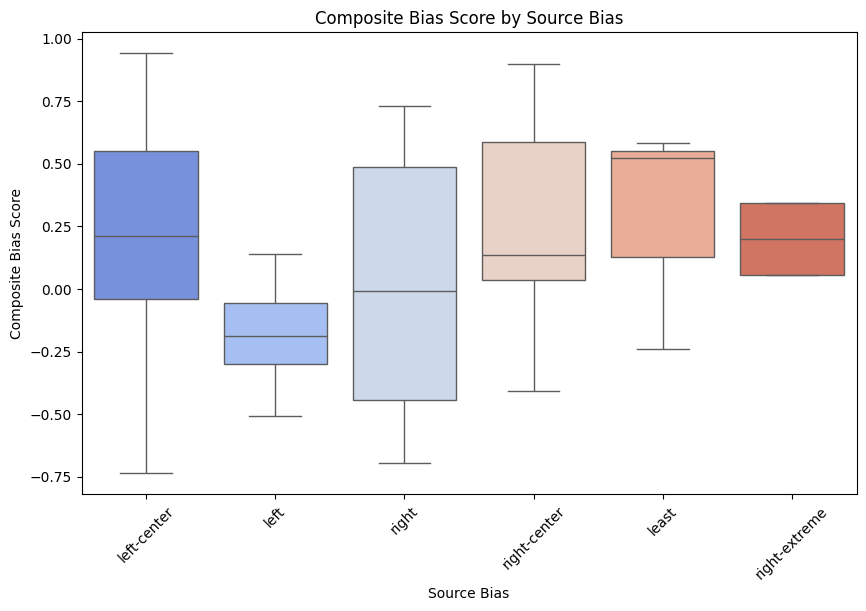

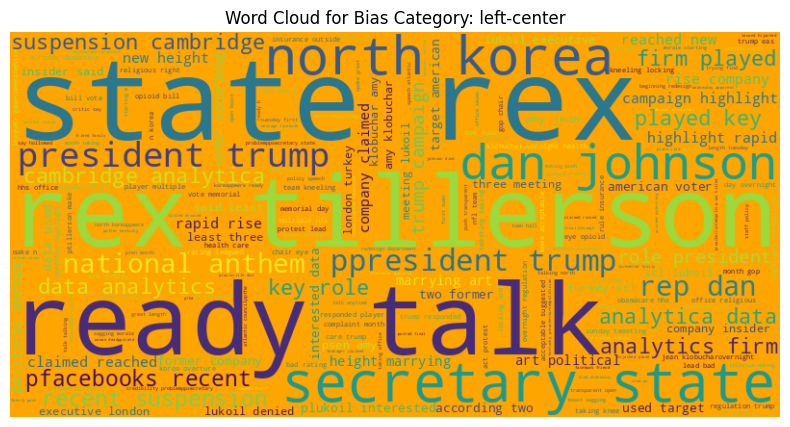

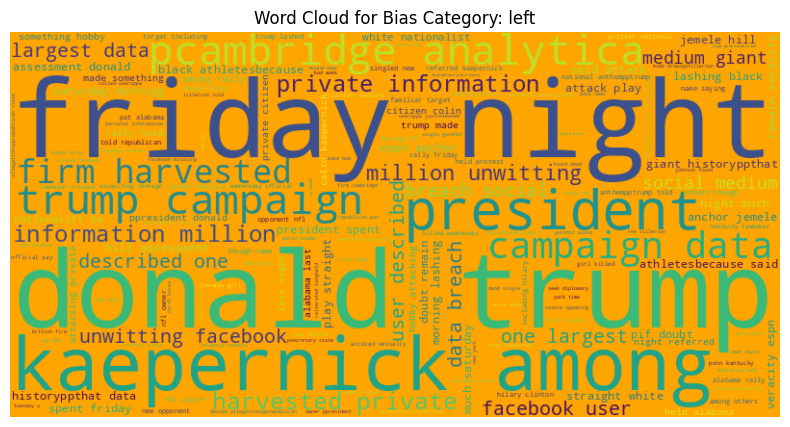

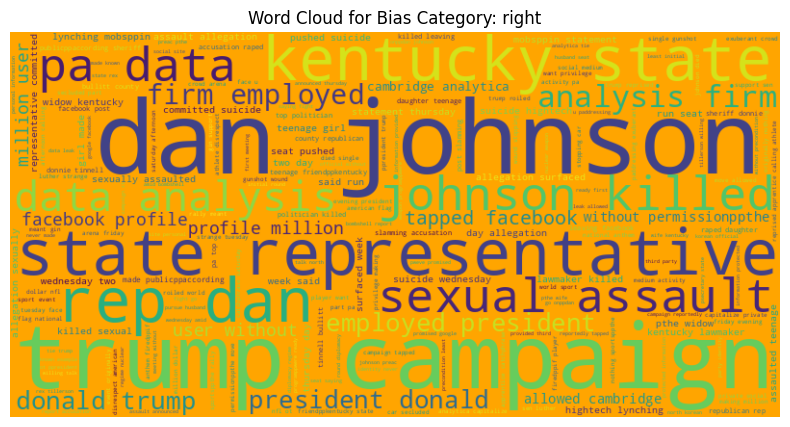

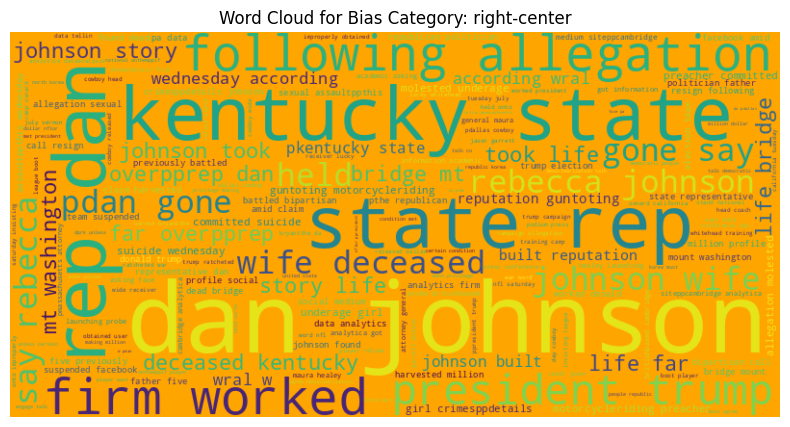

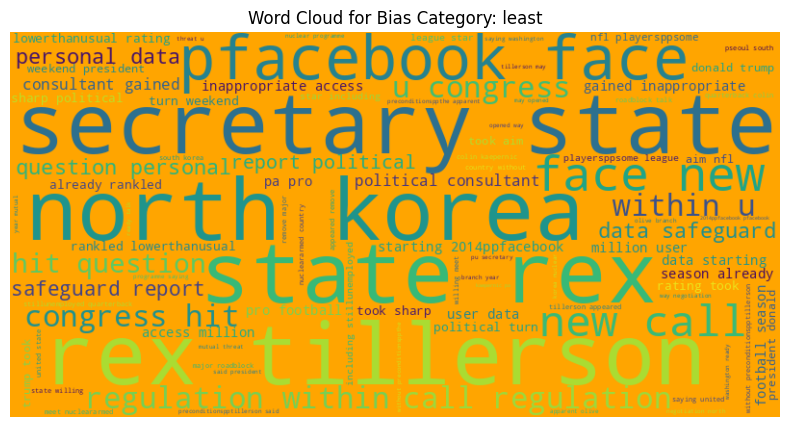

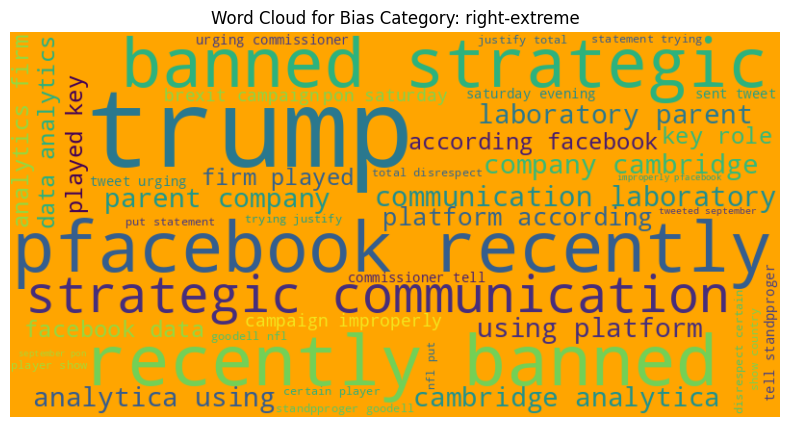

Cross-validation scores: [0.92307692 0.96153846 1.         1.         1.        ]
Average cross-validation score: 0.976923076923077
Random Forest Test Accuracy: 0.8615384615384616
Classification Report:
{'least': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 5}, 'left': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 7}, 'left-center': {'precision': 0.7619047619047619, 'recall': 1.0, 'f1-score': 0.8648648648648648, 'support': 16}, 'right': {'precision': 1.0, 'recall': 0.6086956521739131, 'f1-score': 0.7567567567567568, 'support': 23}, 'right-center': {'precision': 0.75, 'recall': 1.0, 'f1-score': 0.8571428571428571, 'support': 12}, 'right-extreme': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2}, 'accuracy': 0.8615384615384616, 'macro avg': {'precision': 0.9186507936507936, 'recall': 0.9347826086956522, 'f1-score': 0.9131274131274131, 'support': 65}, 'weighted avg': {'precision': 0.8952380952380953, 'recall': 0.8615384615384616, 'f1-score'

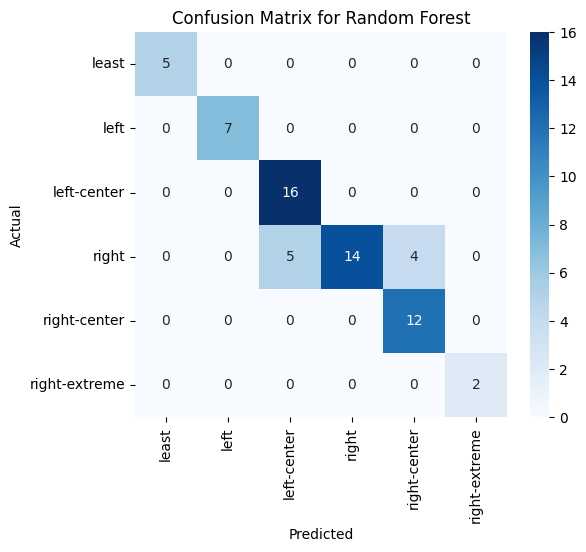

Random Forest Accuracy: 0.8615384615384616


In [34]:
import pandas as pd
import string
import nltk
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from textblob import TextBlob
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

# NLTK Downloads
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

# Load dataset
db = 'Sora_LREC2020_biasedsentences.csv'  
data = pd.read_csv(db)

# Data cleaning
cleaned_db = data.dropna(subset=['reftext', 'docbody'])
cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')

# Normalize text
def normalize_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text)

# Stopwords removal after tokenization
stop_words = set(stopwords.words('english'))

def stopwords_removal_after_tokenization(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return " ".join(filtered_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(stopwords_removal_after_tokenization)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(stopwords_removal_after_tokenization)

# Non-alphabetic characters removal
def non_alpha_numeric_removal(text):
    return ''.join([c for c in text if c.isalnum() or c.isspace()])

cleaned_db['reftext'] = cleaned_db['reftext'].apply(non_alpha_numeric_removal)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(non_alpha_numeric_removal)

# Lemmatization
lemmatizer = WordNetLemmatizer()

def text_lemmatized(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(lemmatized_tokens)

cleaned_db['reftext'] = cleaned_db['reftext'].apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(text_lemmatized)

# Sentiment Analysis - Sentence level sentiment
sia = SentimentIntensityAnalyzer()

def get_sentence_sentiment(text):
    sentences = sent_tokenize(text)
    sentence_sentiments = []
    for sentence in sentences:
        sentiment_score = sia.polarity_scores(sentence)
        sentence_sentiments.append(sentiment_score['compound'])
    return sentence_sentiments

def get_document_sentiment(sentiments):
    return sum(sentiments) / len(sentiments) if sentiments else 0

# Compute TextBlob Subjectivity
def compute_subjectivity(text):
    blob = TextBlob(text)
    return blob.sentiment.subjectivity

cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(compute_subjectivity)

# TF-IDF Vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])

# Encode labels
le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])

# Split the data into training and test sets (now we will also keep the index to map later)
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, cleaned_db['encoded_label'], cleaned_db.index, test_size=0.3, random_state=42
)

# Apply SMOTE for handling class imbalance
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Convert the oversampled X_train_smote back to a DataFrame
X_train_smote_df = pd.DataFrame(X_train_smote.toarray(), columns=vectorizer.get_feature_names_out())

# Apply KMeans clustering on the oversampled training data only
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_train_smote_df)

# Map the KMeans labels back to the oversampled data and then map them to the original indices
cleaned_db.loc[train_idx, 'cluster'] = kmeans_labels[:len(train_idx)]

# Apply LDA (Latent Dirichlet Allocation) on the oversampled training data only
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X_train_smote_df)

# Assign the LDA topic probabilities back to the cleaned_db DataFrame
lda_topic_probs = lda.transform(X_train_smote_df)

# Assign these topic probabilities to the DataFrame
lda_topic_df = pd.DataFrame(lda_topic_probs, columns=[f'lda_topic_{i+1}' for i in range(lda_topic_probs.shape[1])])
cleaned_db.loc[train_idx, lda_topic_df.columns] = lda_topic_df

# Sentiment Analysis for Document Sentiment (only on the training set)
cleaned_db['sentence_sentiments'] = cleaned_db['docbody'].apply(get_sentence_sentiment)
cleaned_db['document_sentiment'] = cleaned_db['sentence_sentiments'].apply(get_document_sentiment)

# Classify sentiment as positive, negative, or neutral
def classify_sentiment_bias(sentiment):
    if sentiment > 0:
        return 'positive'
    elif sentiment < 0:
        return 'negative'
    else:
        return 'neutral'

cleaned_db['document_sentiment_bias'] = cleaned_db['document_sentiment'].apply(classify_sentiment_bias)

# Composite Bias Function
def compute_weighted_composite_bias(row, sentiment_weight=0.8, subjectivity_weight=0.3, cluster_weight=0.3, topic_weight=0.):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    cluster_score = row['cluster']  # KMeans cluster label
    topic_scores = row[[f'lda_topic_{i+1}' for i in range(5)]].values  # LDA topic probabilities

    # Compute the weighted average of the LDA topic probabilities (taking the mean of the topic scores)
    lda_topic_score = topic_scores.mean()  # Mean of the 5 topic scores

    # Compute the final composite bias score
    weighted_score = (sentiment_weight * sentiment_score) + \
                     (subjectivity_weight * subjectivity_score) + \
                     (cluster_weight * cluster_score) + \
                     (topic_weight * lda_topic_score)
    return weighted_score

# Compute the composite bias score
cleaned_db['composite_bias'] = cleaned_db.apply(compute_weighted_composite_bias, axis=1)

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

# Composite Bias Score visualization by Source Bias
plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Word Cloud Generation for each Bias Category
def generate_wordcloud(data, bias_category):
    text = " ".join(data[data['source_bias'] == bias_category]['docbody'])
    wordcloud = WordCloud(width=800, height=400, background_color='orange').generate(text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Bias Category: {bias_category}')
    plt.show()

# Generate Word Clouds for each bias category
for bias in cleaned_db['source_bias'].unique():
    generate_wordcloud(cleaned_db, bias)

# Train a Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)

# Cross-validation for evaluating the Random Forest model
cv_scores_5 = cross_val_score(rf_model, X_train_smote, y_train_smote, cv=5)
print(f"Cross-validation scores: {cv_scores_5}")
print(f"Average cross-validation score: {cv_scores_5.mean()}")

# Predict on the test data
pred_labels5 = rf_model.predict(X_test)
accuracy_run_5 = accuracy_score(y_test, pred_labels5)

# Model evaluation
print(f"Random Forest Test Accuracy: {accuracy_run_5}")
classification_report_5 = classification_report(y_test, pred_labels5, target_names=le.classes_, output_dict=True)
print(f"Classification Report:\n{classification_report_5}")

# Print recall for each class
for label, metrics in classification_report_5.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")

# Confusion Matrix
cm = confusion_matrix(y_test, pred_labels4)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Final Model Results
print(f"Random Forest Accuracy: {accuracy_run_5}")


# Confusion matrix creation based on the bias score on multiple runs 

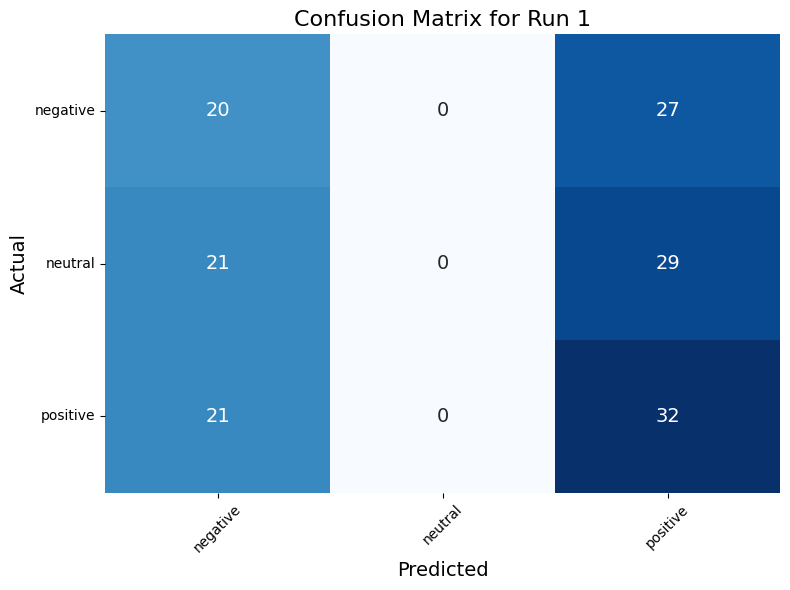


Confusion Matrix for Run 1:
[[20  0 27]
 [21  0 29]
 [21  0 32]]


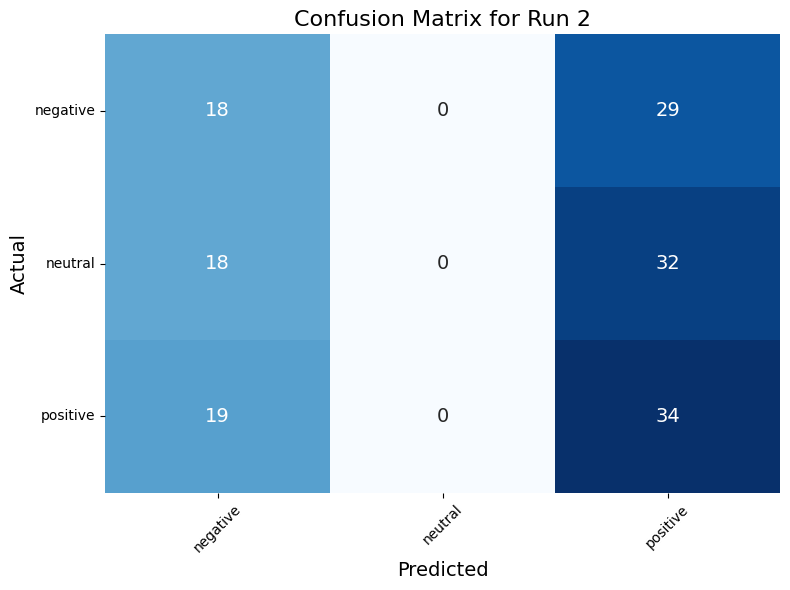


Confusion Matrix for Run 2:
[[18  0 29]
 [18  0 32]
 [19  0 34]]


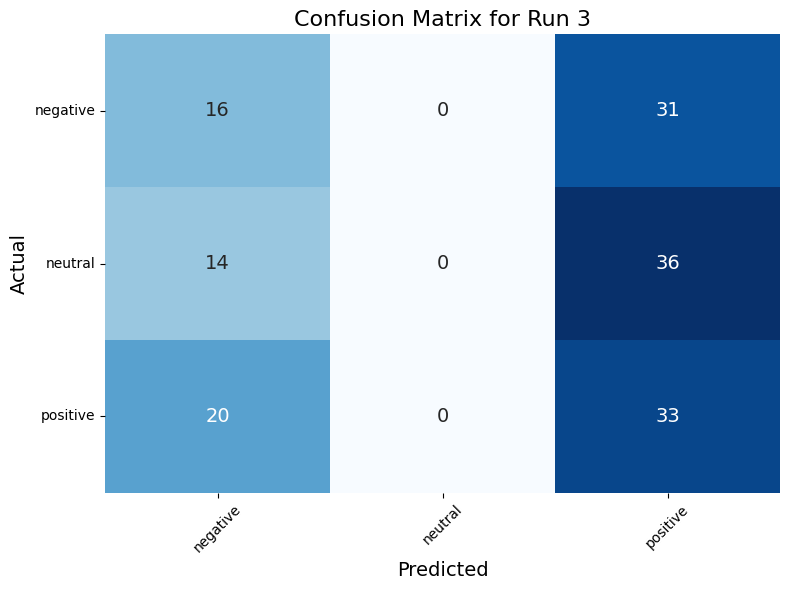


Confusion Matrix for Run 3:
[[16  0 31]
 [14  0 36]
 [20  0 33]]


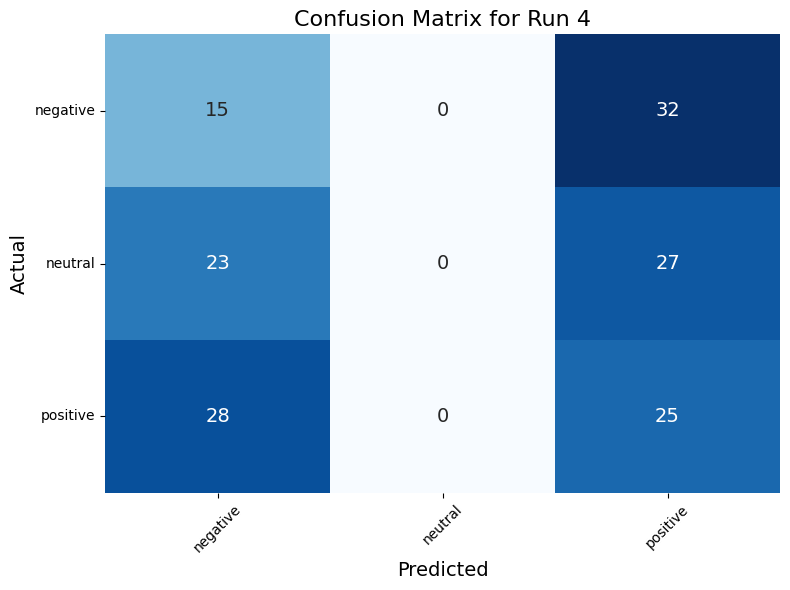


Confusion Matrix for Run 4:
[[15  0 32]
 [23  0 27]
 [28  0 25]]


In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Function to classify bias scores into 'negative', 'neutral', and 'positive'
def classify_bias_score(bias_score):
    if bias_score < 0:
        return 'negative'
    elif bias_score == 0:
        return 'neutral'
    else:
        return 'positive'

# Run summaries for each "run" (Mean, Std, Min, Max as given)
runs = {
    'Run 1': {'mean': 0.127561, 'std': 0.437039, 'min': -0.736080, 'max': 0.941793},
    'Run 2': {'mean': 0.127561, 'std': 0.437039, 'min': -0.736080, 'max': 0.941793},
    'Run 3': {'mean': 0.112117, 'std': 0.300754, 'min': -0.476055, 'max': 0.696431},
    'Run 4': {'mean': 0.127561, 'std': 0.437039, 'min': -0.736080, 'max': 0.941793}
}

# Generate synthetic bias scores for each run based on the provided mean and std
np.random.seed(42)  # Ensuring reproducibility

run_bias_scores = {}
for run, stats in runs.items():
    run_bias_scores[run] = np.random.normal(stats['mean'], stats['std'], 150)  # 150 is an arbitrary sample size

# Sample true labels (Replace with your actual labels from the dataset)
# Assuming the dataset has true labels encoded as 'negative', 'neutral', 'positive'
true_labels = np.random.choice(['negative', 'neutral', 'positive'], size=150)  # Replace with actual true labels

# Step 2: Create confusion matrices for each run
for run, bias_scores in run_bias_scores.items():
    # Classify bias scores into 'negative', 'neutral', 'positive' categories
    predicted_labels = [classify_bias_score(score) for score in bias_scores]

    # Compute confusion matrix
    cm = confusion_matrix(true_labels, predicted_labels, labels=['negative', 'neutral', 'positive'])
    
    # Visualization of confusion matrix using seaborn's heatmap
    plt.figure(figsize=(8, 6))  # Adjusted figure size for better readability
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=['negative', 'neutral', 'positive'], 
                yticklabels=['negative', 'neutral', 'positive'], cbar=False, annot_kws={"size": 14})
    plt.title(f"Confusion Matrix for {run}", fontsize=16)
    plt.xlabel('Predicted', fontsize=14)
    plt.ylabel('Actual', fontsize=14)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()  # Ensures no clipping of labels
    plt.show()
    
    # Print the confusion matrix for each run
    print(f"\nConfusion Matrix for {run}:")
    print(cm)


# Temporal Analysis of Bias(Monthly  Basis)

   id_event    event  date_event  id_article                 source  \
0         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
1         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
2         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
3         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
4         1  Johnson  2017-12-15         2.0              002_CNN_1   

   source_bias                                                url      ref  \
0  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
1  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
2  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
3  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
4         left  http://www.cnn.com/2017/12/14/us/kentucky-stat...  Reuters   

                                             ref_url  article_bias  ...  \
0  https://www.reuters.com/ar

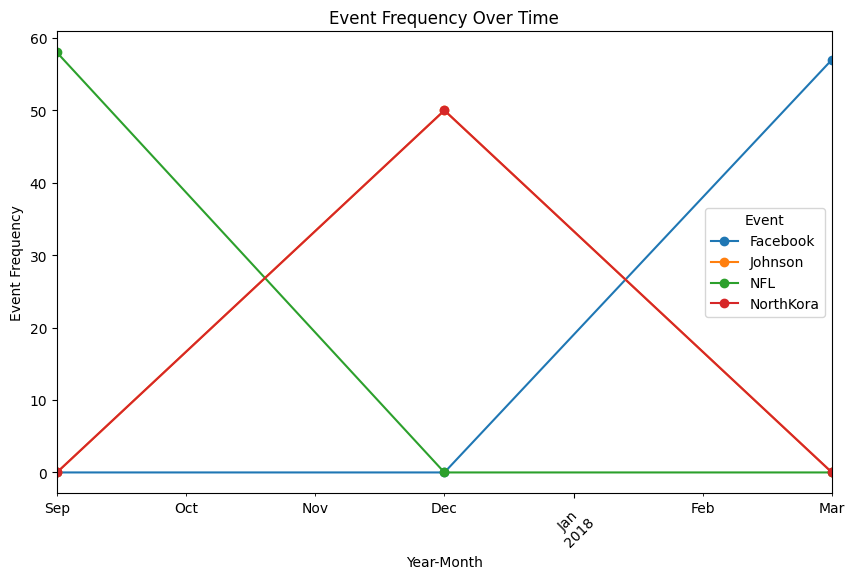

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

db = 'Sora_LREC2020_biasedsentences.csv'  

data = pd.read_csv(db)

print(data.head())
data = data.dropna(subset=['date_event', 'event'])  
data['date_event'] = pd.to_datetime(data['date_event'], errors='coerce')  
data = data.dropna(subset=['date_event'])

#Considering only the month and year from the date_event column
data['year'] = data['date_event'].dt.year
data['month'] = data['date_event'].dt.month
data['year_month'] = data['date_event'].dt.to_period('M') 

event_count_by_time = data.groupby(['year_month', 'event']).size().unstack(fill_value=0)
event_count_by_time.plot(kind='line', marker='o', figsize=(10, 6))
plt.title('Event Frequency Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Event Frequency')
plt.xticks(rotation=45)
plt.legend(title='Event')
plt.show()


# Temporal analysis of Bias(Daily Basis)

   id_event    event  date_event  id_article                 source  \
0         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
1         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
2         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
3         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
4         1  Johnson  2017-12-15         2.0              002_CNN_1   

   source_bias                                                url      ref  \
0  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
1  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
2  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
3  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
4         left  http://www.cnn.com/2017/12/14/us/kentucky-stat...  Reuters   

                                             ref_url  article_bias  ...  \
0  https://www.reuters.com/ar

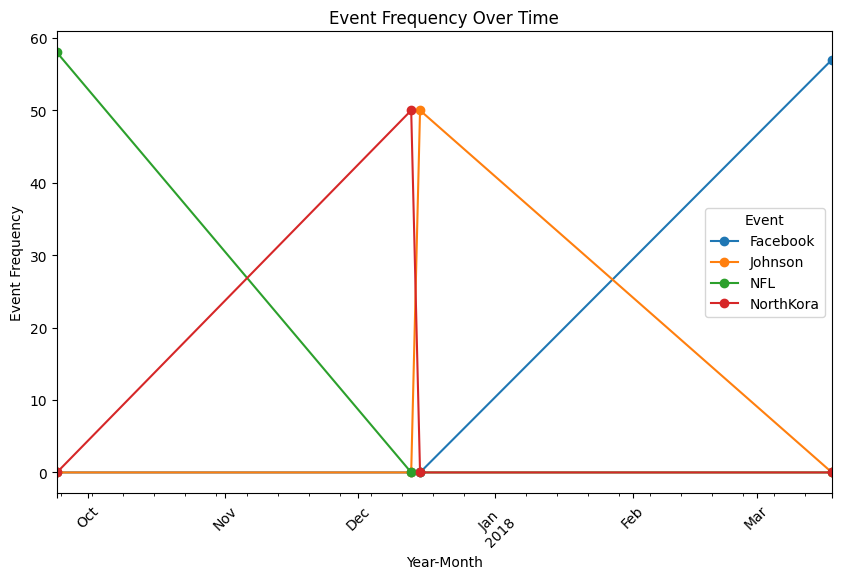

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

db = 'Sora_LREC2020_biasedsentences.csv'  

data = pd.read_csv(db)

print(data.head())
data = data.dropna(subset=['date_event', 'event'])  
data['date_event'] = pd.to_datetime(data['date_event'], errors='coerce')  
data = data.dropna(subset=['date_event'])

#Considering only the daily basis from the date_event column
data['year'] = data['date_event'].dt.year
data['month'] = data['date_event'].dt.month
data['year_month'] = data['date_event'].dt.to_period('D') 

event_count_by_time = data.groupby(['year_month', 'event']).size().unstack(fill_value=0)
event_count_by_time.plot(kind='line', marker='o', figsize=(10, 6))
plt.title('Event Frequency Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Event Frequency')
plt.xticks(rotation=45)
plt.legend(title='Event')
plt.show()


# Temporal Analysis of Bias(Weekly Basis)

   id_event    event  date_event  id_article                 source  \
0         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
1         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
2         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
3         1  Johnson  2017-12-15         1.0  001_Washington Post_1   
4         1  Johnson  2017-12-15         2.0              002_CNN_1   

   source_bias                                                url      ref  \
0  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
1  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
2  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
3  left-center  https://www.washingtonpost.com/news/post-natio...  Reuters   
4         left  http://www.cnn.com/2017/12/14/us/kentucky-stat...  Reuters   

                                             ref_url  article_bias  ...  \
0  https://www.reuters.com/ar

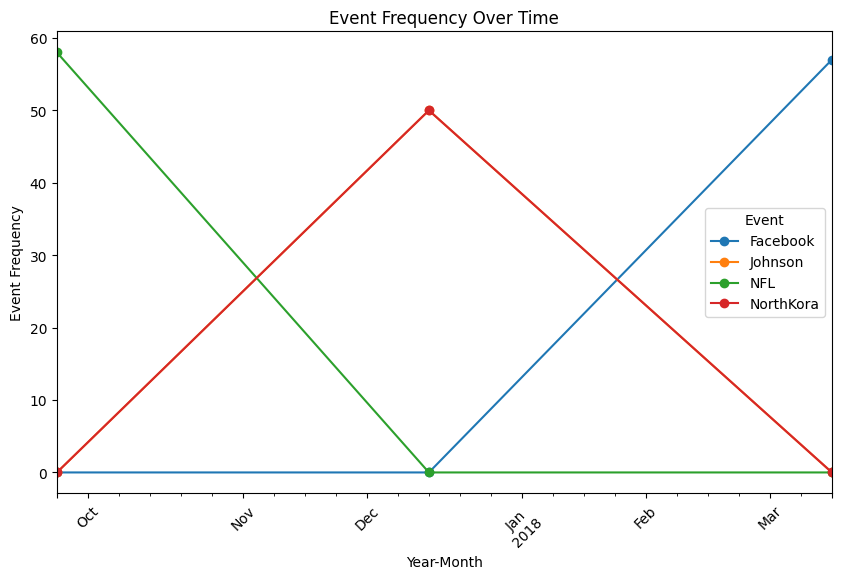

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

db = 'Sora_LREC2020_biasedsentences.csv'  

data = pd.read_csv(db)

print(data.head())
data = data.dropna(subset=['date_event', 'event'])  
data['date_event'] = pd.to_datetime(data['date_event'], errors='coerce')  
data = data.dropna(subset=['date_event'])

#Considering only the weekly basis from the date_event column
data['year'] = data['date_event'].dt.year
data['month'] = data['date_event'].dt.month
data['year_month'] = data['date_event'].dt.to_period('W') 

event_count_by_time = data.groupby(['year_month', 'event']).size().unstack(fill_value=0)
event_count_by_time.plot(kind='line', marker='o', figsize=(10, 6))
plt.title('Event Frequency Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Event Frequency')
plt.xticks(rotation=45)
plt.legend(title='Event')
plt.show()


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=75d44bbd-9133-469d-b355-d63cbf0e2b98' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>